# Domain Analysis

# Bussiness Case:-
 * Create a predictive model  using machine learning techniques to predict the various classes of skin disease

## DataSet Information


#### Class

*  1: psoriasis
*  2: seboreic dermatitis
*  3: lichen planus
*  4: pityriasis rosea
*  5: cronic dermatitis
*  6: pityriasis rubra pilaris

#### Family history:

*  1: if any of these diseases has been observed in the family
*  0: otherwise

#### Age:

*  Represents the age of the patient

#### All other attributes:

*  0: feature not present
*  1,2 indicate the relative intermediate values
*  3 indicates the largest amount possible

In [2]:
import pandas as pd # Importing Pandas for data manipulation and analysis
import numpy as np # Importing NumPy for numerical calculations and array operations
import matplotlib.pyplot as plt # Importing Matplotlib for creating graphs and visualizations
import seaborn as sns # Importing Seaborn for creating attractive statistical graphs
import warnings # Importing the warnings module to manage warning messages
warnings.filterwarnings("ignore") # Ignoring warning messages to keep the output clean

In [3]:
pd.set_option("display.max_columns",None) # show total columns

In [4]:
df = pd.read_csv("skindisorderdata.csv") # Loading the Skin Disorder Prediction CSV dataset into a Df variable

In [5]:
df.head()# showing first 5 row of the data

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,0,0,0,0,0,3,2,0,0,0,0,0,0,0,0,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,1,0,0,1,0,1,2,0,2,2,2,2,2,1,0,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,0,1,0,0,0,1,2,0,2,0,0,0,0,0,2,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,0,0,0,3,0,0,2,0,3,2,2,2,2,0,0,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,0,1,0,0,0,1,2,0,0,0,0,0,0,0,2,2,3,2,3,0,0,2,3,45,3


In [6]:
df.tail() # showing last 5 row of the data

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
361,2,1,1,0,1,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,2,0,25,4
362,3,2,1,0,1,0,0,0,0,0,0,0,0,0,0,2,2,0,0,0,0,0,0,0,0,1,0,1,0,0,0,2,0,36,4
363,3,2,2,2,3,2,0,2,0,0,0,2,2,0,0,3,3,0,0,0,0,0,0,0,3,0,3,0,3,0,0,2,3,28,3
364,2,1,3,1,2,3,0,2,0,0,0,2,0,0,0,3,2,0,0,0,0,0,0,0,3,0,2,0,1,0,0,2,3,50,3
365,3,2,2,0,0,0,0,0,3,3,0,0,0,1,0,0,2,0,2,3,2,3,0,2,0,2,0,0,0,0,0,3,0,35,1


In [7]:
df.shape # show all records and features

(366, 35)

In [8]:
df.info() #dataset information of each and every columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   erythema                                  366 non-null    int64 
 1   scaling                                   366 non-null    int64 
 2   definite_borders                          366 non-null    int64 
 3   itching                                   366 non-null    int64 
 4   koebner_phenomenon                        366 non-null    int64 
 5   polygonal_papules                         366 non-null    int64 
 6   follicular_papules                        366 non-null    int64 
 7   oral_mucosal_involvement                  366 non-null    int64 
 8   knee_and_elbow_involvement                366 non-null    int64 
 9   scalp_involvement                         366 non-null    int64 
 10  family_history                            366 non-

#### Insights

* Age column is in object,we have to convert in integers.

In [9]:
df.columns # shows columns names

Index(['erythema', 'scaling', 'definite_borders', 'itching',
       'koebner_phenomenon', 'polygonal_papules', 'follicular_papules',
       'oral_mucosal_involvement', 'knee_and_elbow_involvement',
       'scalp_involvement', 'family_history', 'melanin_incontinence',
       'eosinophils_in_the_infiltrate', 'PNL_infiltrate',
       'fibrosis_of_the_papillary_dermis', 'exocytosis', 'acanthosis',
       'hyperkeratosis', 'parakeratosis', 'clubbing_of_the_rete_ridges',
       'elongation_of_the_rete_ridges',
       'thinning_of_the_suprapapillary_epidermis', 'spongiform_pustule',
       'munro_microabcess', 'focal_hypergranulosis',
       'disappearance_of_the_granular_layer',
       'vacuolisation_and_damage_of_basal_layer', 'spongiosis',
       'saw-tooth_appearance_of_retes', 'follicular_horn_plug',
       'perifollicular_parakeratosis', 'inflammatory_monoluclear_inflitrate',
       'band-like_infiltrate', 'Age', 'class'],
      dtype='object')

In [10]:
df.dtypes # Display the data type of each column in the DataFrame

erythema                                     int64
scaling                                      int64
definite_borders                             int64
itching                                      int64
koebner_phenomenon                           int64
polygonal_papules                            int64
follicular_papules                           int64
oral_mucosal_involvement                     int64
knee_and_elbow_involvement                   int64
scalp_involvement                            int64
family_history                               int64
melanin_incontinence                         int64
eosinophils_in_the_infiltrate                int64
PNL_infiltrate                               int64
fibrosis_of_the_papillary_dermis             int64
exocytosis                                   int64
acanthosis                                   int64
hyperkeratosis                               int64
parakeratosis                                int64
clubbing_of_the_rete_ridges    

In [11]:
df.isnull().sum() # Count the number of missing (null) values in each column of the DataFrame

erythema                                    0
scaling                                     0
definite_borders                            0
itching                                     0
koebner_phenomenon                          0
polygonal_papules                           0
follicular_papules                          0
oral_mucosal_involvement                    0
knee_and_elbow_involvement                  0
scalp_involvement                           0
family_history                              0
melanin_incontinence                        0
eosinophils_in_the_infiltrate               0
PNL_infiltrate                              0
fibrosis_of_the_papillary_dermis            0
exocytosis                                  0
acanthosis                                  0
hyperkeratosis                              0
parakeratosis                               0
clubbing_of_the_rete_ridges                 0
elongation_of_the_rete_ridges               0
thinning_of_the_suprapapillary_epi

In [12]:
df.isnull().sum().sum() #Dataset contains no missing values.

np.int64(0)

In [13]:
df.duplicated().sum()  # Count duplicate rows in the dataset

np.int64(0)

In [14]:
df.describe() # statistical information only numerical columns

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,class
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,2.068306,1.795082,1.549180,1.366120,0.633880,0.448087,0.166667,0.377049,0.614754,0.519126,0.125683,0.404372,0.139344,0.546448,0.336066,1.368852,1.956284,0.527322,1.289617,0.663934,0.991803,0.633880,0.295082,0.363388,0.393443,0.464481,0.456284,0.953552,0.453552,0.103825,0.114754,1.866120,0.554645,2.803279
std,0.664753,0.701527,0.907525,1.138299,0.908016,0.957327,0.570588,0.834147,0.982979,0.905639,0.331946,0.869818,0.411790,0.815451,0.853139,1.104418,0.712512,0.757116,0.917562,1.056829,1.162161,1.034924,0.670578,0.759721,0.849406,0.864899,0.954873,1.130172,0.954744,0.450433,0.488723,0.726108,1.105908,1.597803
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
50%,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,3.000000
75%,2.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,2.000000,0.000000,4.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,1.000000,3.000000,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,6.000000


In [15]:
df["class"].value_counts()# Target Value Counts

class
1    112
3     72
2     61
5     52
4     49
6     20
Name: count, dtype: int64

In [16]:
df["class"].value_counts(normalize=True) * 100 #Target Percentage

class
1    30.601093
3    19.672131
2    16.666667
5    14.207650
4    13.387978
6     5.464481
Name: proportion, dtype: float64

In [17]:
for col in df.columns: # Loop through all columns
    print(col, ":", df[col].unique())  # Display unique values in each column

erythema : [2 3 1 0]
scaling : [2 3 1 0]
definite_borders : [0 3 2 1]
itching : [3 2 0 1]
koebner_phenomenon : [0 1 2 3]
polygonal_papules : [0 3 2 1]
follicular_papules : [0 3 1 2]
oral_mucosal_involvement : [0 3 2 1]
knee_and_elbow_involvement : [1 0 3 2]
scalp_involvement : [0 1 2 3]
family_history : [0 1]
melanin_incontinence : [0 1 2 3]
eosinophils_in_the_infiltrate : [0 2 1]
PNL_infiltrate : [0 1 3 2]
fibrosis_of_the_papillary_dermis : [0 3 1 2]
exocytosis : [3 1 0 2]
acanthosis : [2 3 1 0]
hyperkeratosis : [0 2 1 3]
parakeratosis : [0 2 3 1]
clubbing_of_the_rete_ridges : [0 2 1 3]
elongation_of_the_rete_ridges : [0 2 3 1]
thinning_of_the_suprapapillary_epidermis : [0 2 3 1]
spongiform_pustule : [0 2 1 3]
munro_microabcess : [0 1 2 3]
focal_hypergranulosis : [0 2 3 1]
disappearance_of_the_granular_layer : [0 3 2 1]
vacuolisation_and_damage_of_basal_layer : [0 2 3 1]
spongiosis : [3 0 2 1]
saw-tooth_appearance_of_retes : [0 2 3 1]
follicular_horn_plug : [0 1 2 3]
perifollicular_pa

In [18]:
df.nunique() #Number of Unique Values

erythema                                     4
scaling                                      4
definite_borders                             4
itching                                      4
koebner_phenomenon                           4
polygonal_papules                            4
follicular_papules                           4
oral_mucosal_involvement                     4
knee_and_elbow_involvement                   4
scalp_involvement                            4
family_history                               2
melanin_incontinence                         4
eosinophils_in_the_infiltrate                3
PNL_infiltrate                               4
fibrosis_of_the_papillary_dermis             4
exocytosis                                   4
acanthosis                                   4
hyperkeratosis                               4
parakeratosis                                4
clubbing_of_the_rete_ridges                  4
elongation_of_the_rete_ridges                4
thinning_of_t

# EDA

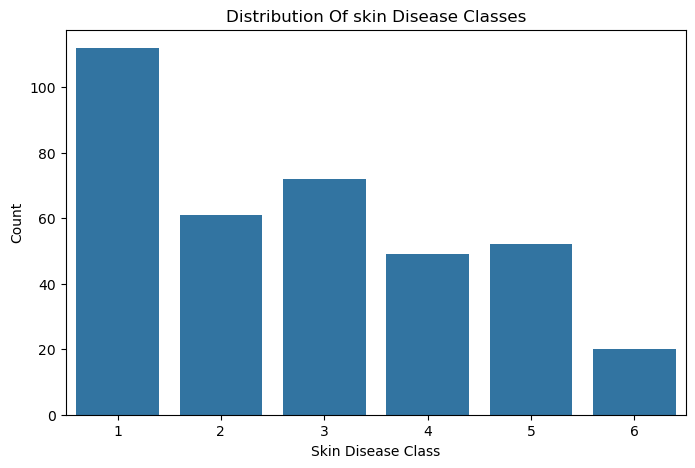

In [19]:
plt.figure(figsize=(8,5))  # Set figure size
sns.countplot(x="class",data=df) # Count samples in each class
plt.title("Distribution Of skin Disease Classes") # Set plot title
plt.xlabel("Skin Disease Class") # Set x-axis label
plt.ylabel("Count") # Set y-axis label
plt.show()  # Display the plot

### Insight:
* Shows the count and distribution of each skin disease class.

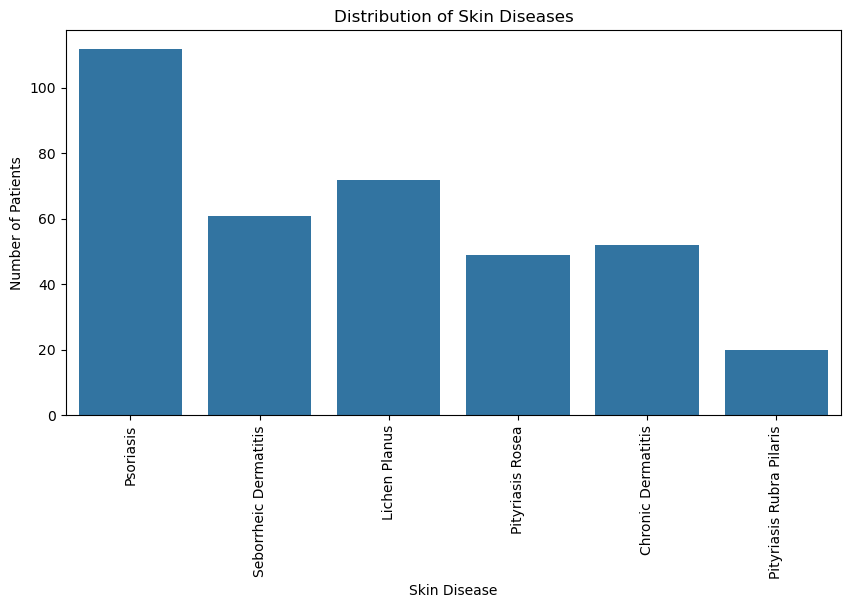

In [20]:
class_name = {1:"Psoriasis", 2:"Seborrheic Dermatitis", 3:"Lichen Planus", 4:"Pityriasis Rosea", 5:"Chronic Dermatitis", 6:"Pityriasis Rubra Pilaris"}  # Map class numbers to disease names
class_counts = df["class"].value_counts().sort_index()  # Count each class in order
plt.figure(figsize=(10,5))  # Set figure size
sns.barplot(x=class_counts.index, y=class_counts.values)  # Plot disease counts
plt.xticks(ticks=range(len(class_counts)), labels=[class_name[i] for i in class_counts.index], rotation=90)  # Display disease names
plt.title("Distribution of Skin Diseases")  # Set plot title
plt.xlabel("Skin Disease")  # Label x-axis
plt.ylabel("Number of Patients")  # Label y-axis
plt.show()  # Display graph

### Insight: 
* Shows the number of patients in each skin disease class and helps identify class imbalance.

In [21]:
print(df["class"].value_counts().sort_index())  # Count records in each class
print(df["class"].value_counts(normalize=True).sort_index() * 100)  # Calculate class percentages

class
1    112
2     61
3     72
4     49
5     52
6     20
Name: count, dtype: int64
class
1    30.601093
2    16.666667
3    19.672131
4    13.387978
5    14.207650
6     5.464481
Name: proportion, dtype: float64


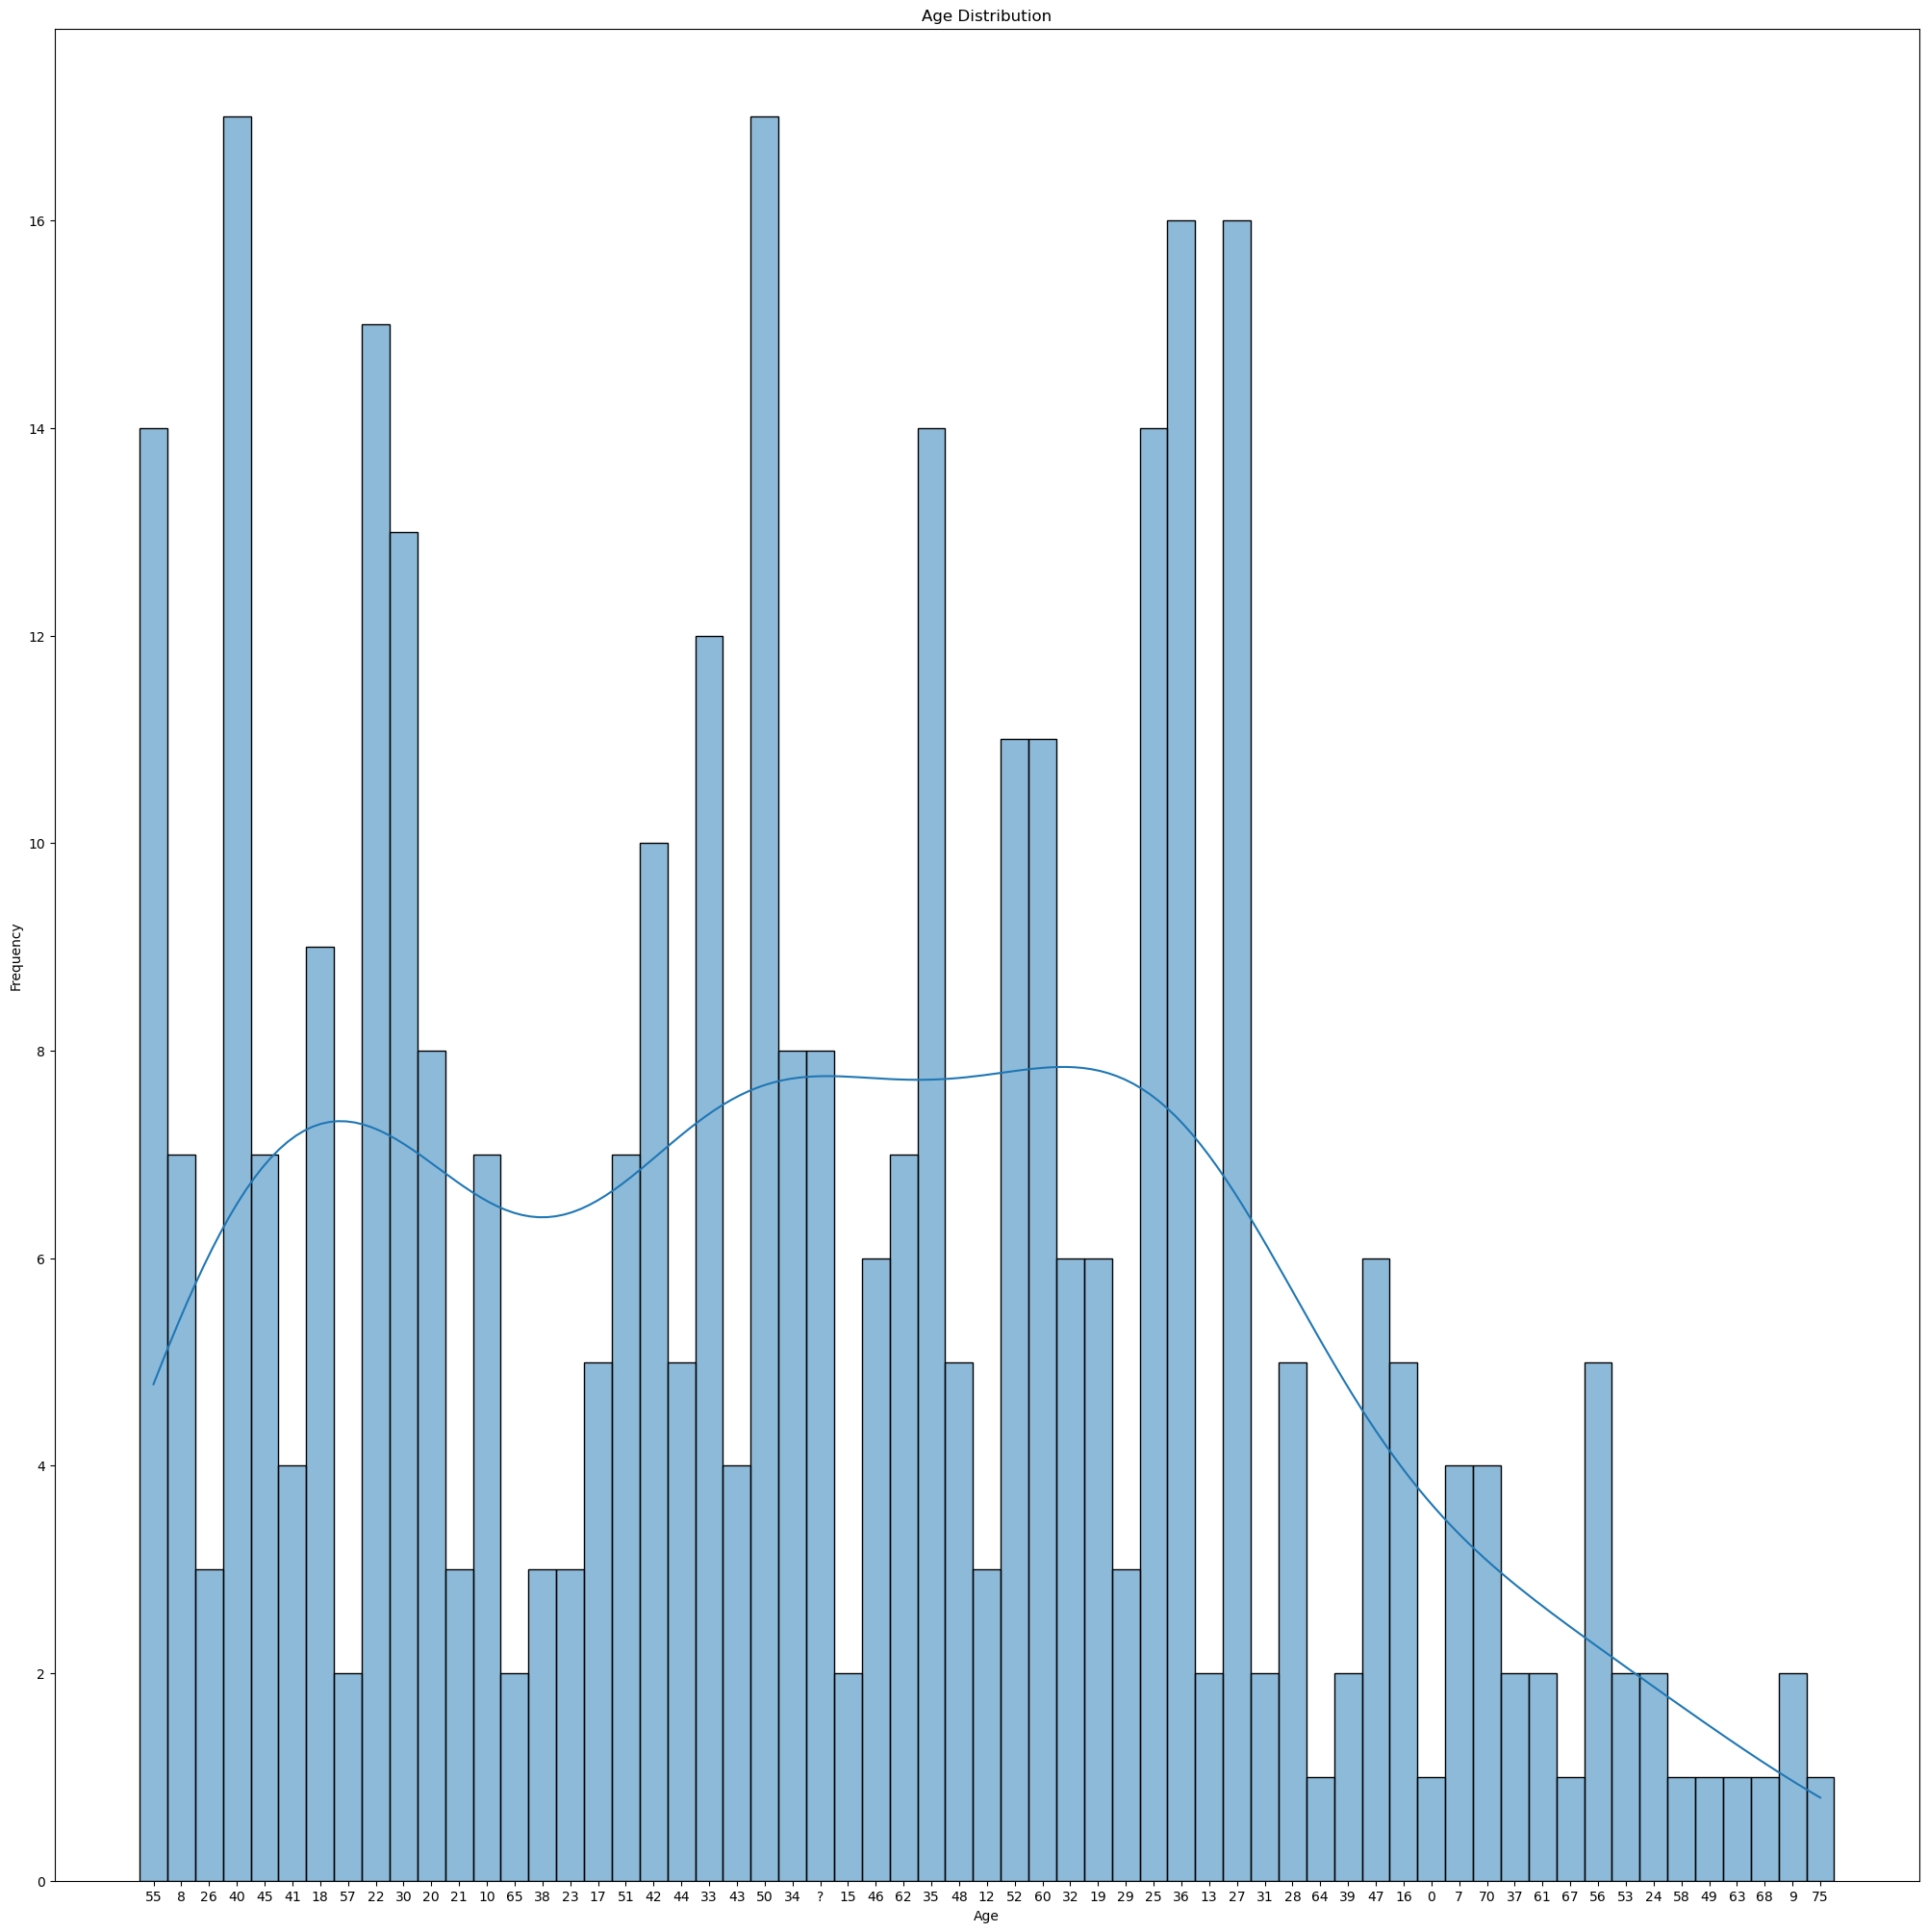

In [24]:
plt.figure(figsize=(25,25))  # Set figure size
sns.histplot(x=df.Age, kde=True)  # Plot age distribution with density curve
plt.title("Age Distribution")  # Set plot title
plt.xlabel("Age")  # Label x-axis
plt.ylabel("Frequency")  # Label y-axis
plt.show()  # Display graph

### Insight: 
* Shows the age distribution of patients and identifies the most common age range and the overall spread of ages.

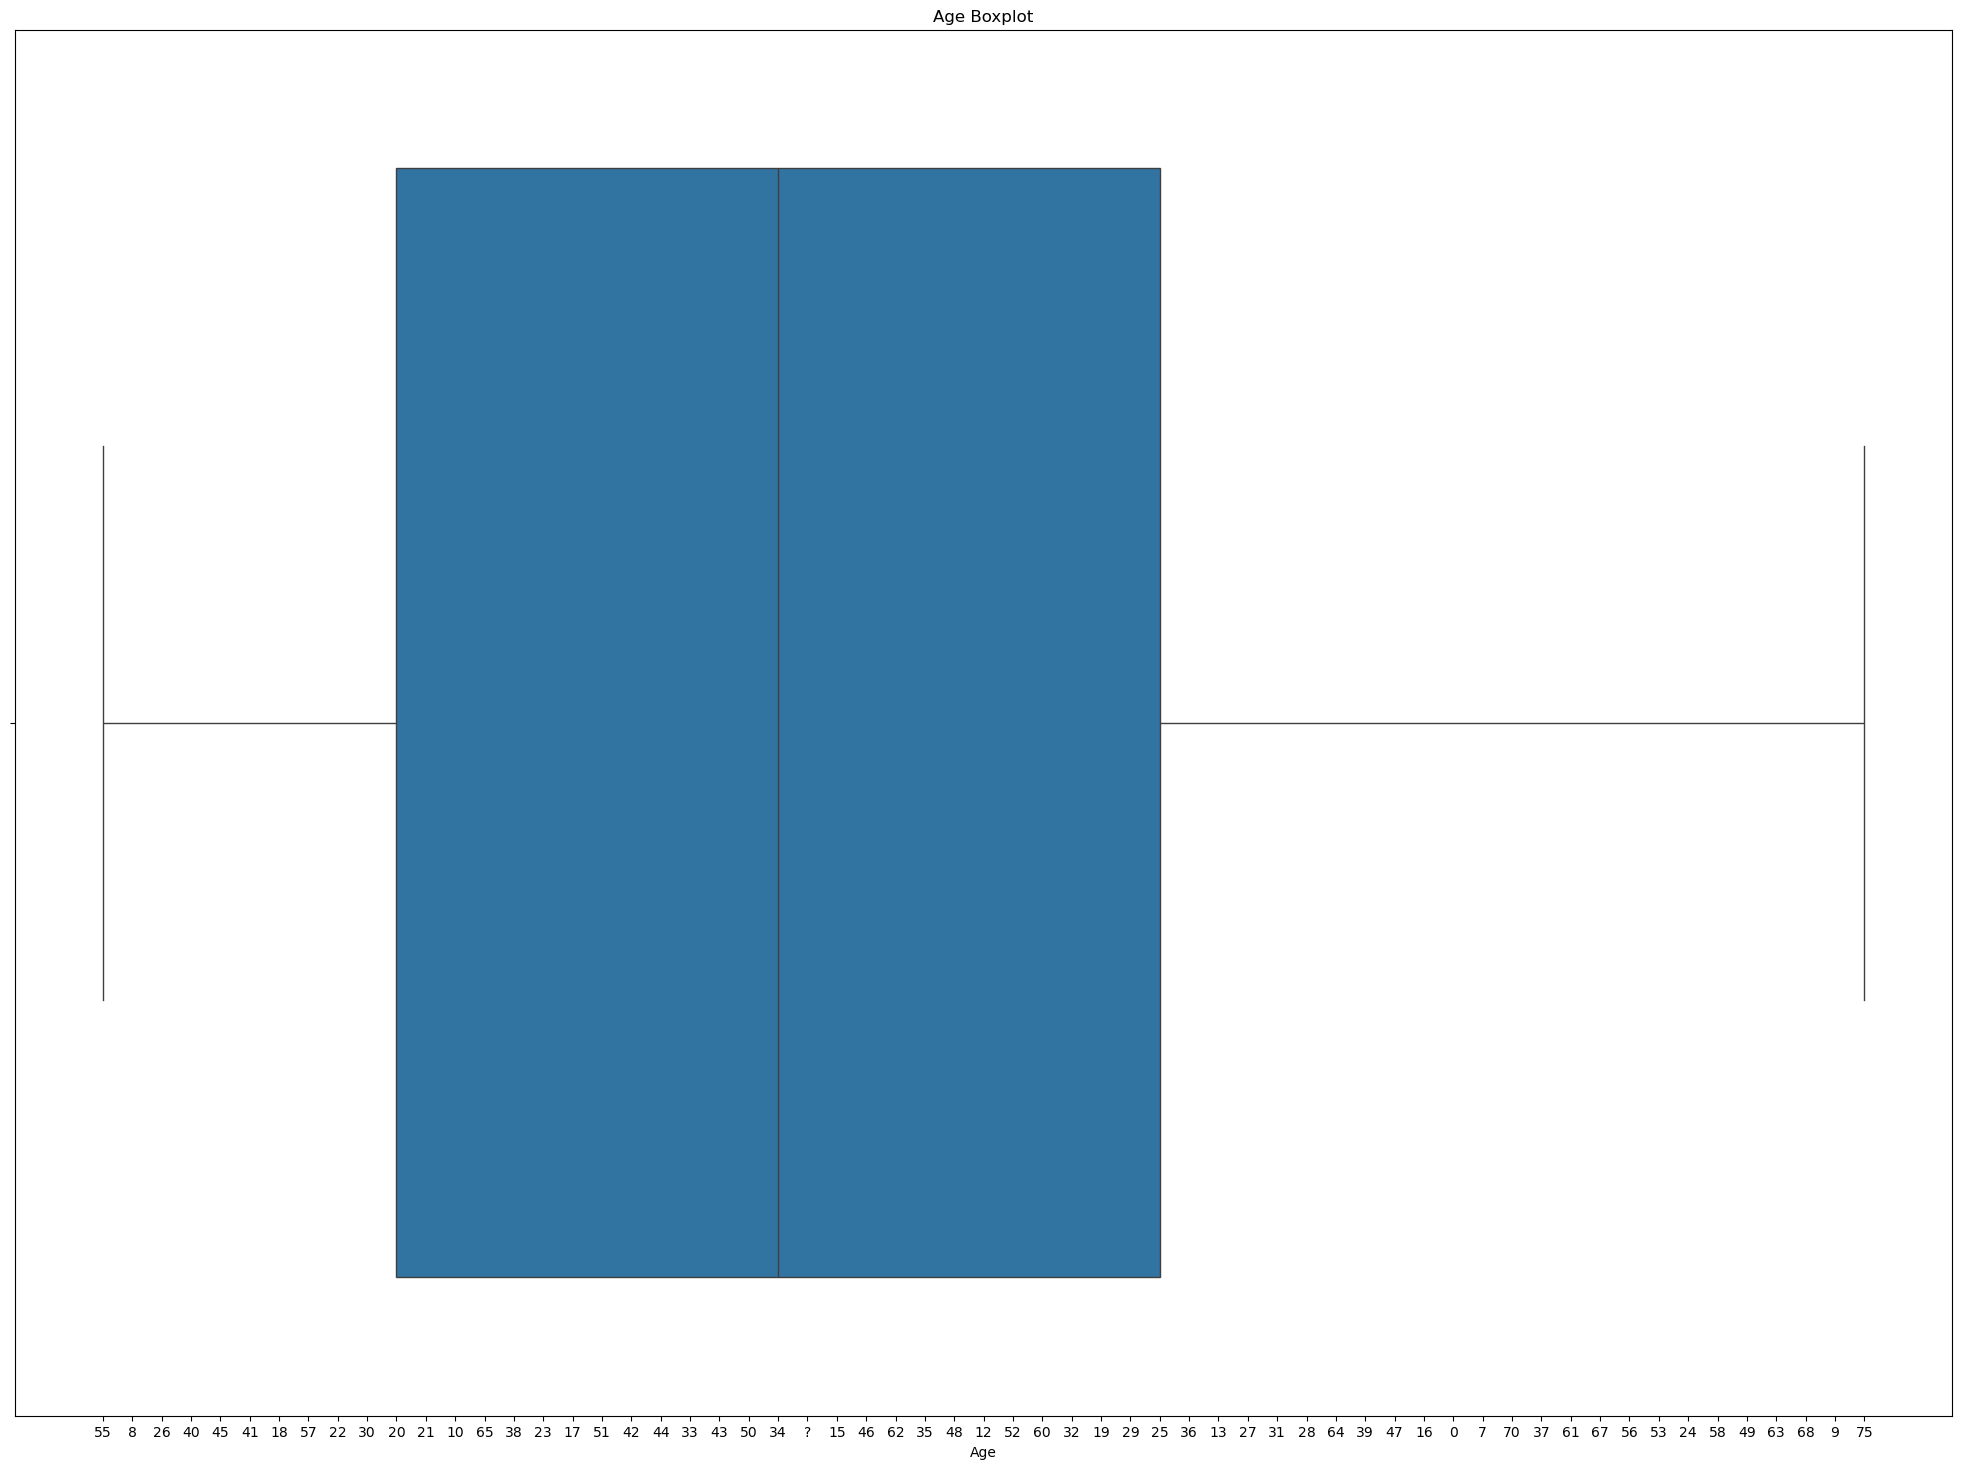

In [30]:
plt.figure(figsize=(25,18))  # Set figure size
sns.boxplot(x=df["Age"])  # Display age outliers and spread
plt.title("Age Boxplot")  # Set plot title
plt.xlabel("Age")  # Label x-axis
plt.show()  # Display graph

### Insight: 
* Identifies the age distribution, median, spread, and potential outliers in the dataset.

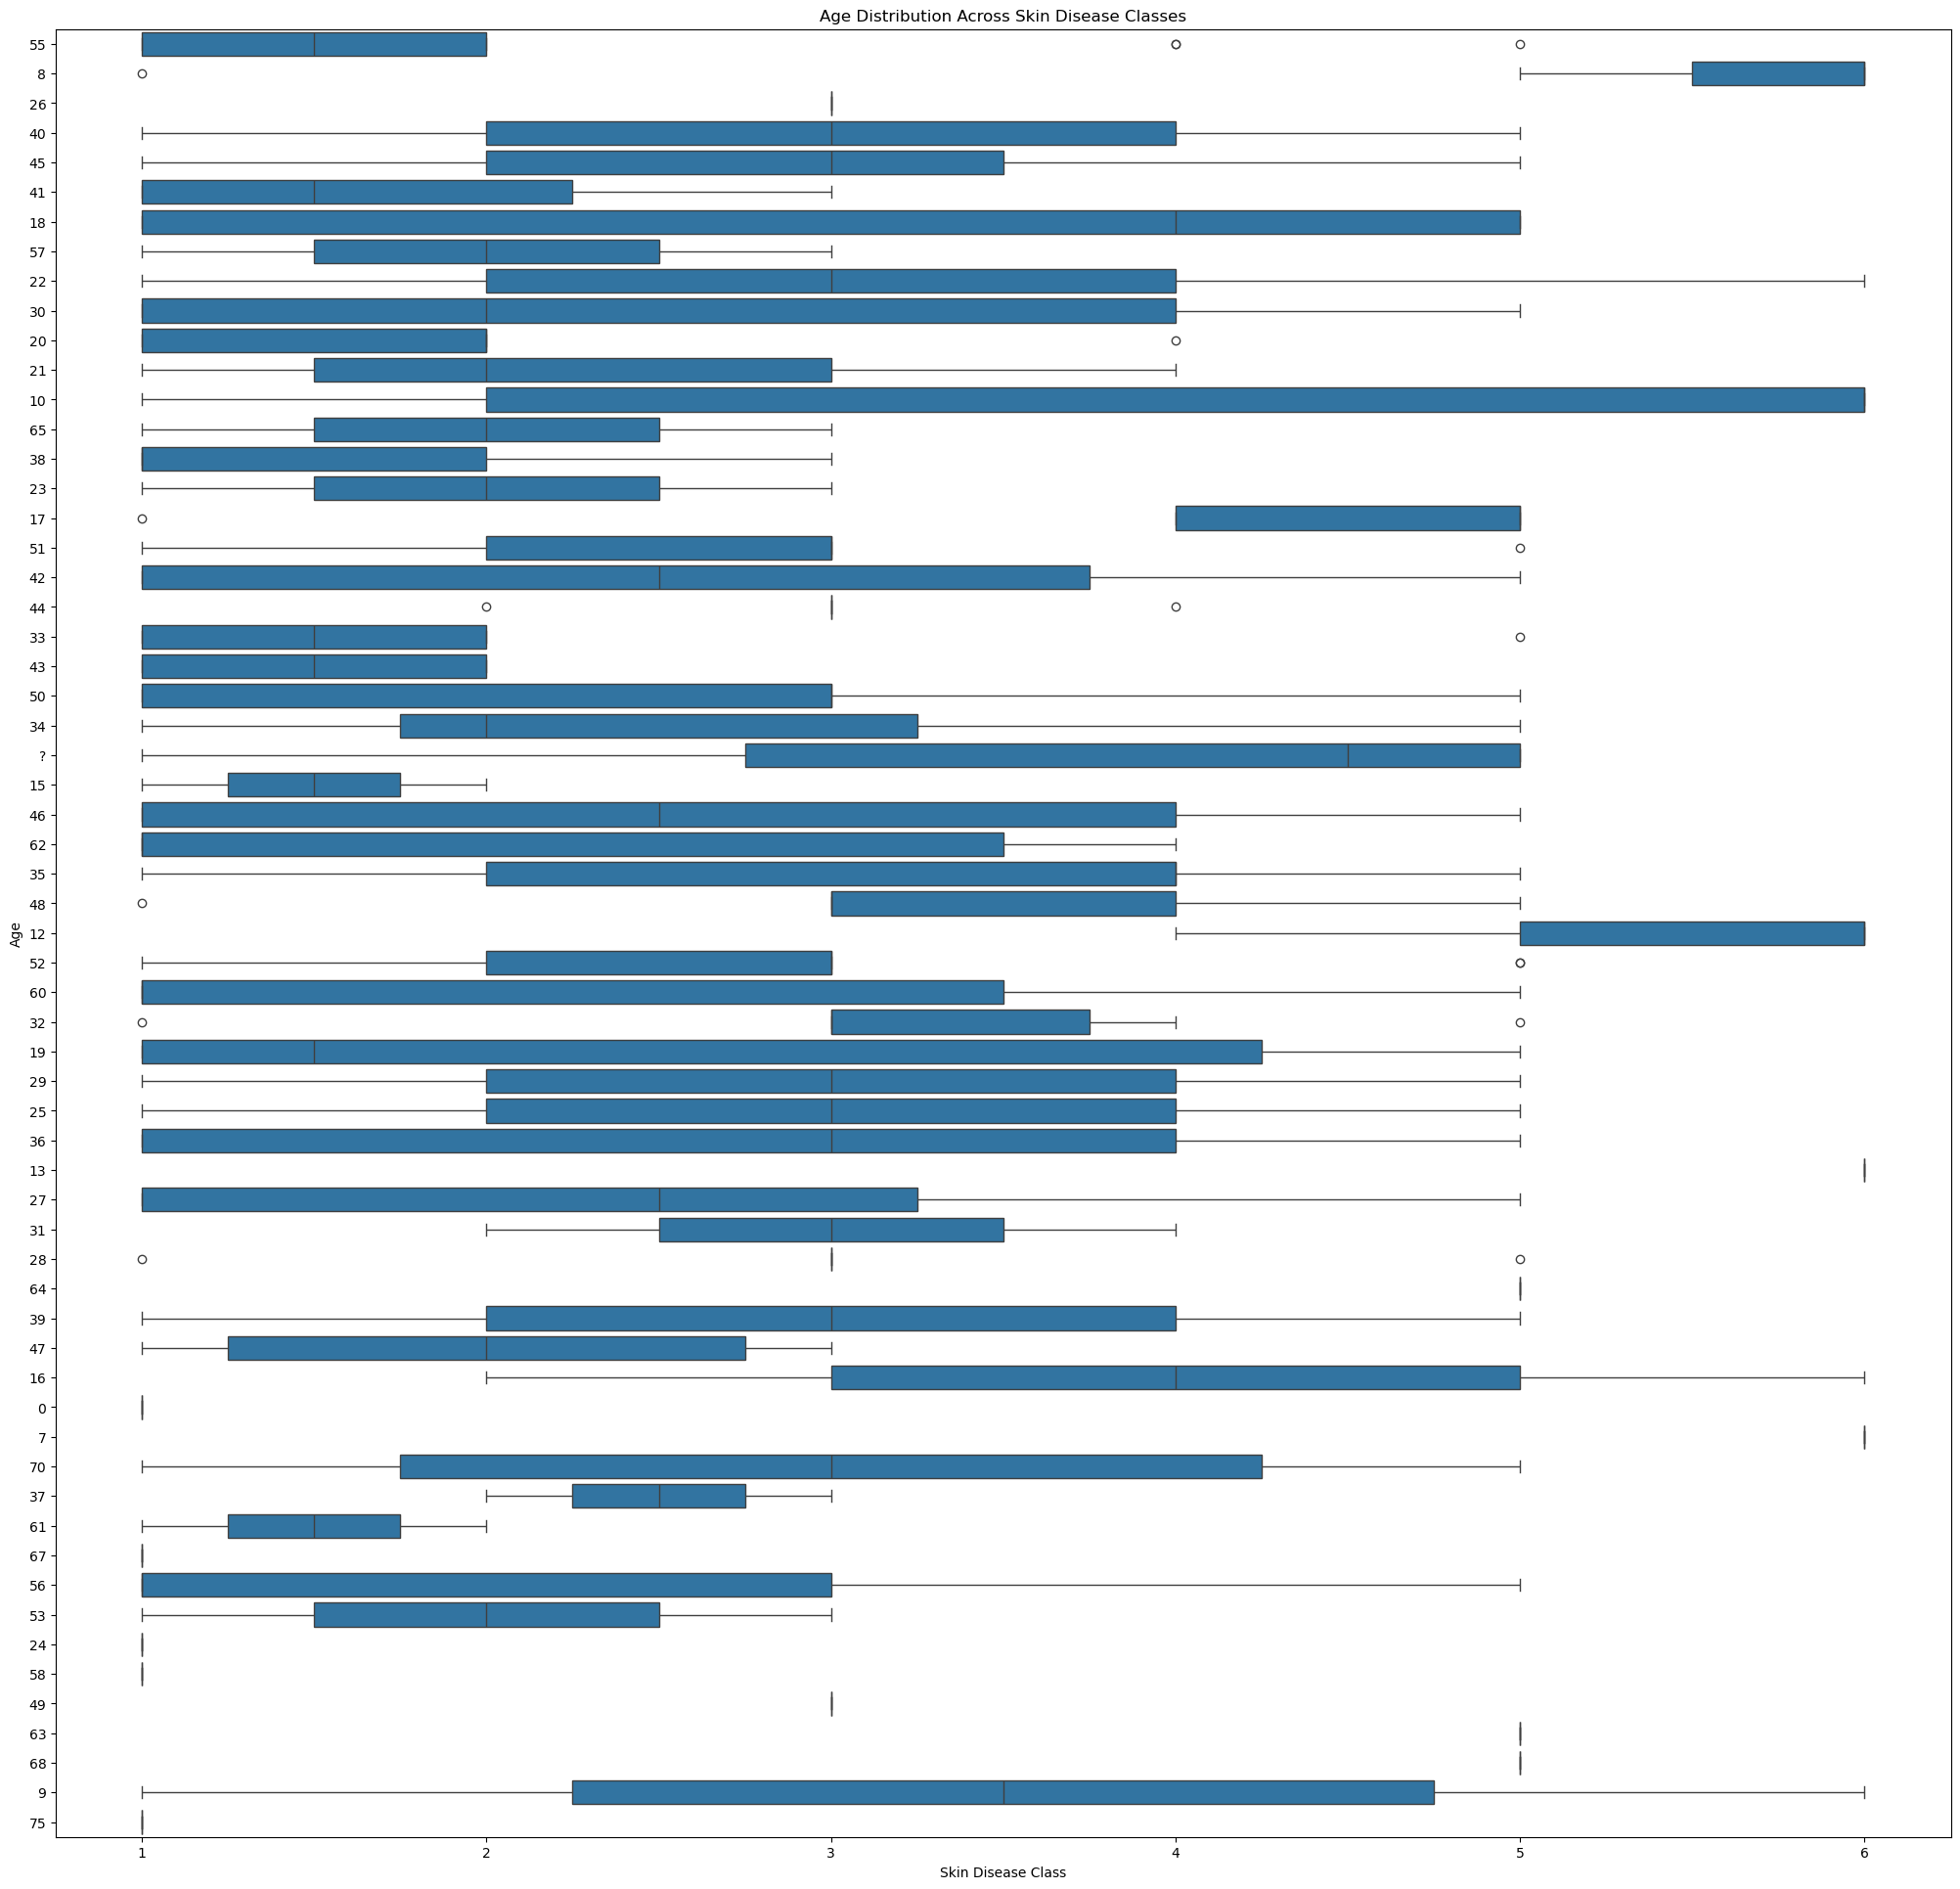

In [33]:
plt.figure(figsize=(25,24))  # Set figure size
sns.boxplot(x="class", y="Age", data=df)  # Compare age across disease classes
plt.title("Age Distribution Across Skin Disease Classes")  # Set plot title
plt.xlabel("Skin Disease Class")  # Label x-axis
plt.ylabel("Age")  # Label y-axis
plt.show()  # Display graph

### Insight: 
* Compares age distribution across skin disease classes and identifies differences in median age, spread, and potential outliers.

In [34]:
feature_cols = df.columns.drop(["Age", "class"])  # Select feature columns except Age and target

for col in feature_cols:  # Loop through each feature
    print(col, ":", sorted(df[col].unique()))  # Display sorted unique values

erythema : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
scaling : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
definite_borders : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
itching : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
koebner_phenomenon : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
polygonal_papules : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
follicular_papules : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
oral_mucosal_involvement : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
knee_and_elbow_involvement : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
scalp_involvement : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
family_history : [np.int64(0), np.int64(1)]
melanin_incontinence : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
eosinophils_in_the_infiltrate : [np.int64(0), np.int64(1), np.int64(2)]
PNL_infiltrate : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
fibrosis_of_the_papi

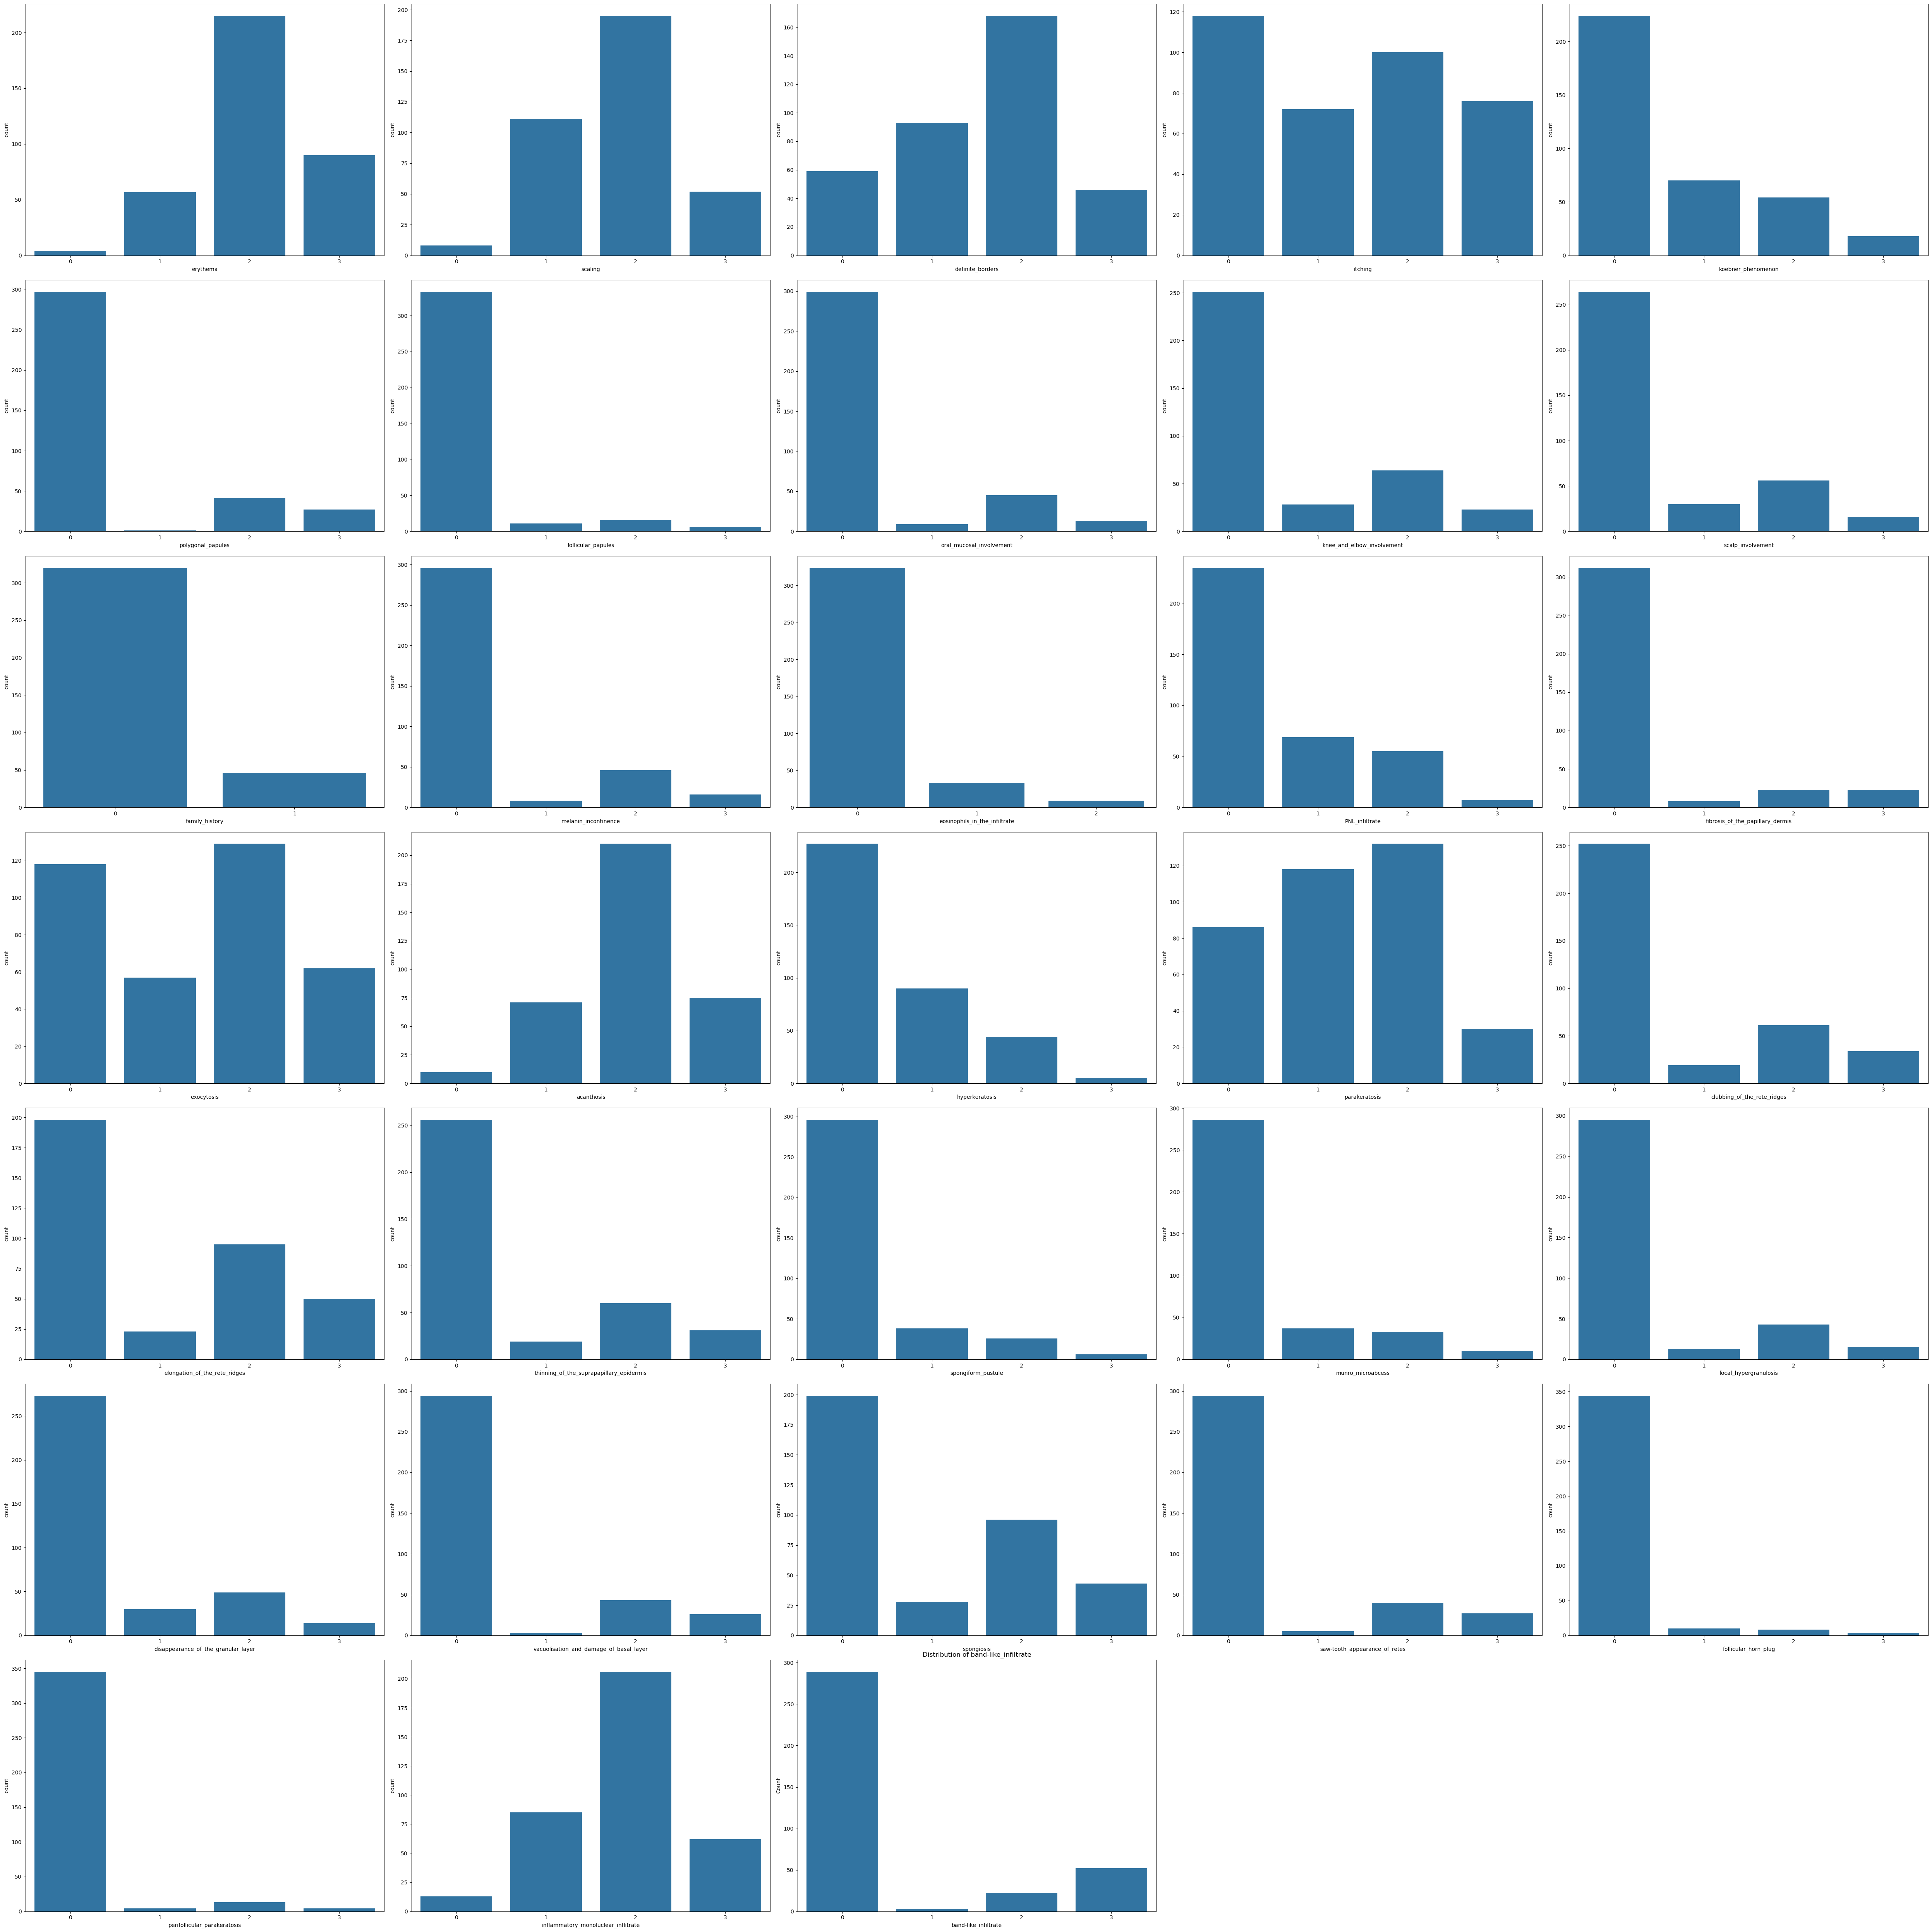

In [35]:
plt.figure(figsize=(50,50))  # Set figure size
num = 1  # Initialize subplot position
for col in feature_cols:  # Loop through feature columns
    plt.subplot(7,5,num)  # Create subplot
    sns.countplot(data=df, x=col)  # Plot feature value counts
    num = num + 1  # Move to next subplot
plt.tight_layout()  # Adjust subplot spacing
plt.title(f"Distribution of {col}")  # Set plot title
plt.xlabel(col)  # Label x-axis
plt.ylabel("Count")  # Label y-axis
plt.show()  # Display all plots

### Insight: 
* Shows the frequency distribution of each feature and helps identify common values, rare values, and potential class imbalances.

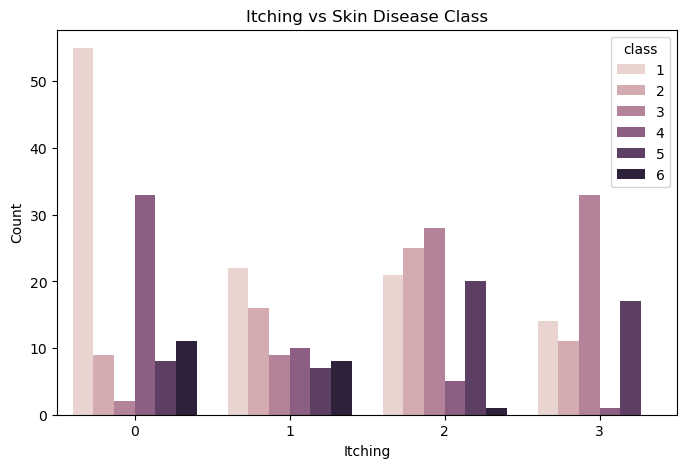

In [36]:
plt.figure(figsize=(8,5))  # Set figure size
sns.countplot(x="itching", hue="class", data=df)  # Compare itching across disease classes
plt.title("Itching vs Skin Disease Class")  # Set plot title
plt.xlabel("Itching")  # Label x-axis
plt.ylabel("Count")  # Label y-axis
plt.show()  # Display graph

### Insight: 
* Shows the relationship between itching and skin disease classes, helping identify how itching frequency varies across different diseases.

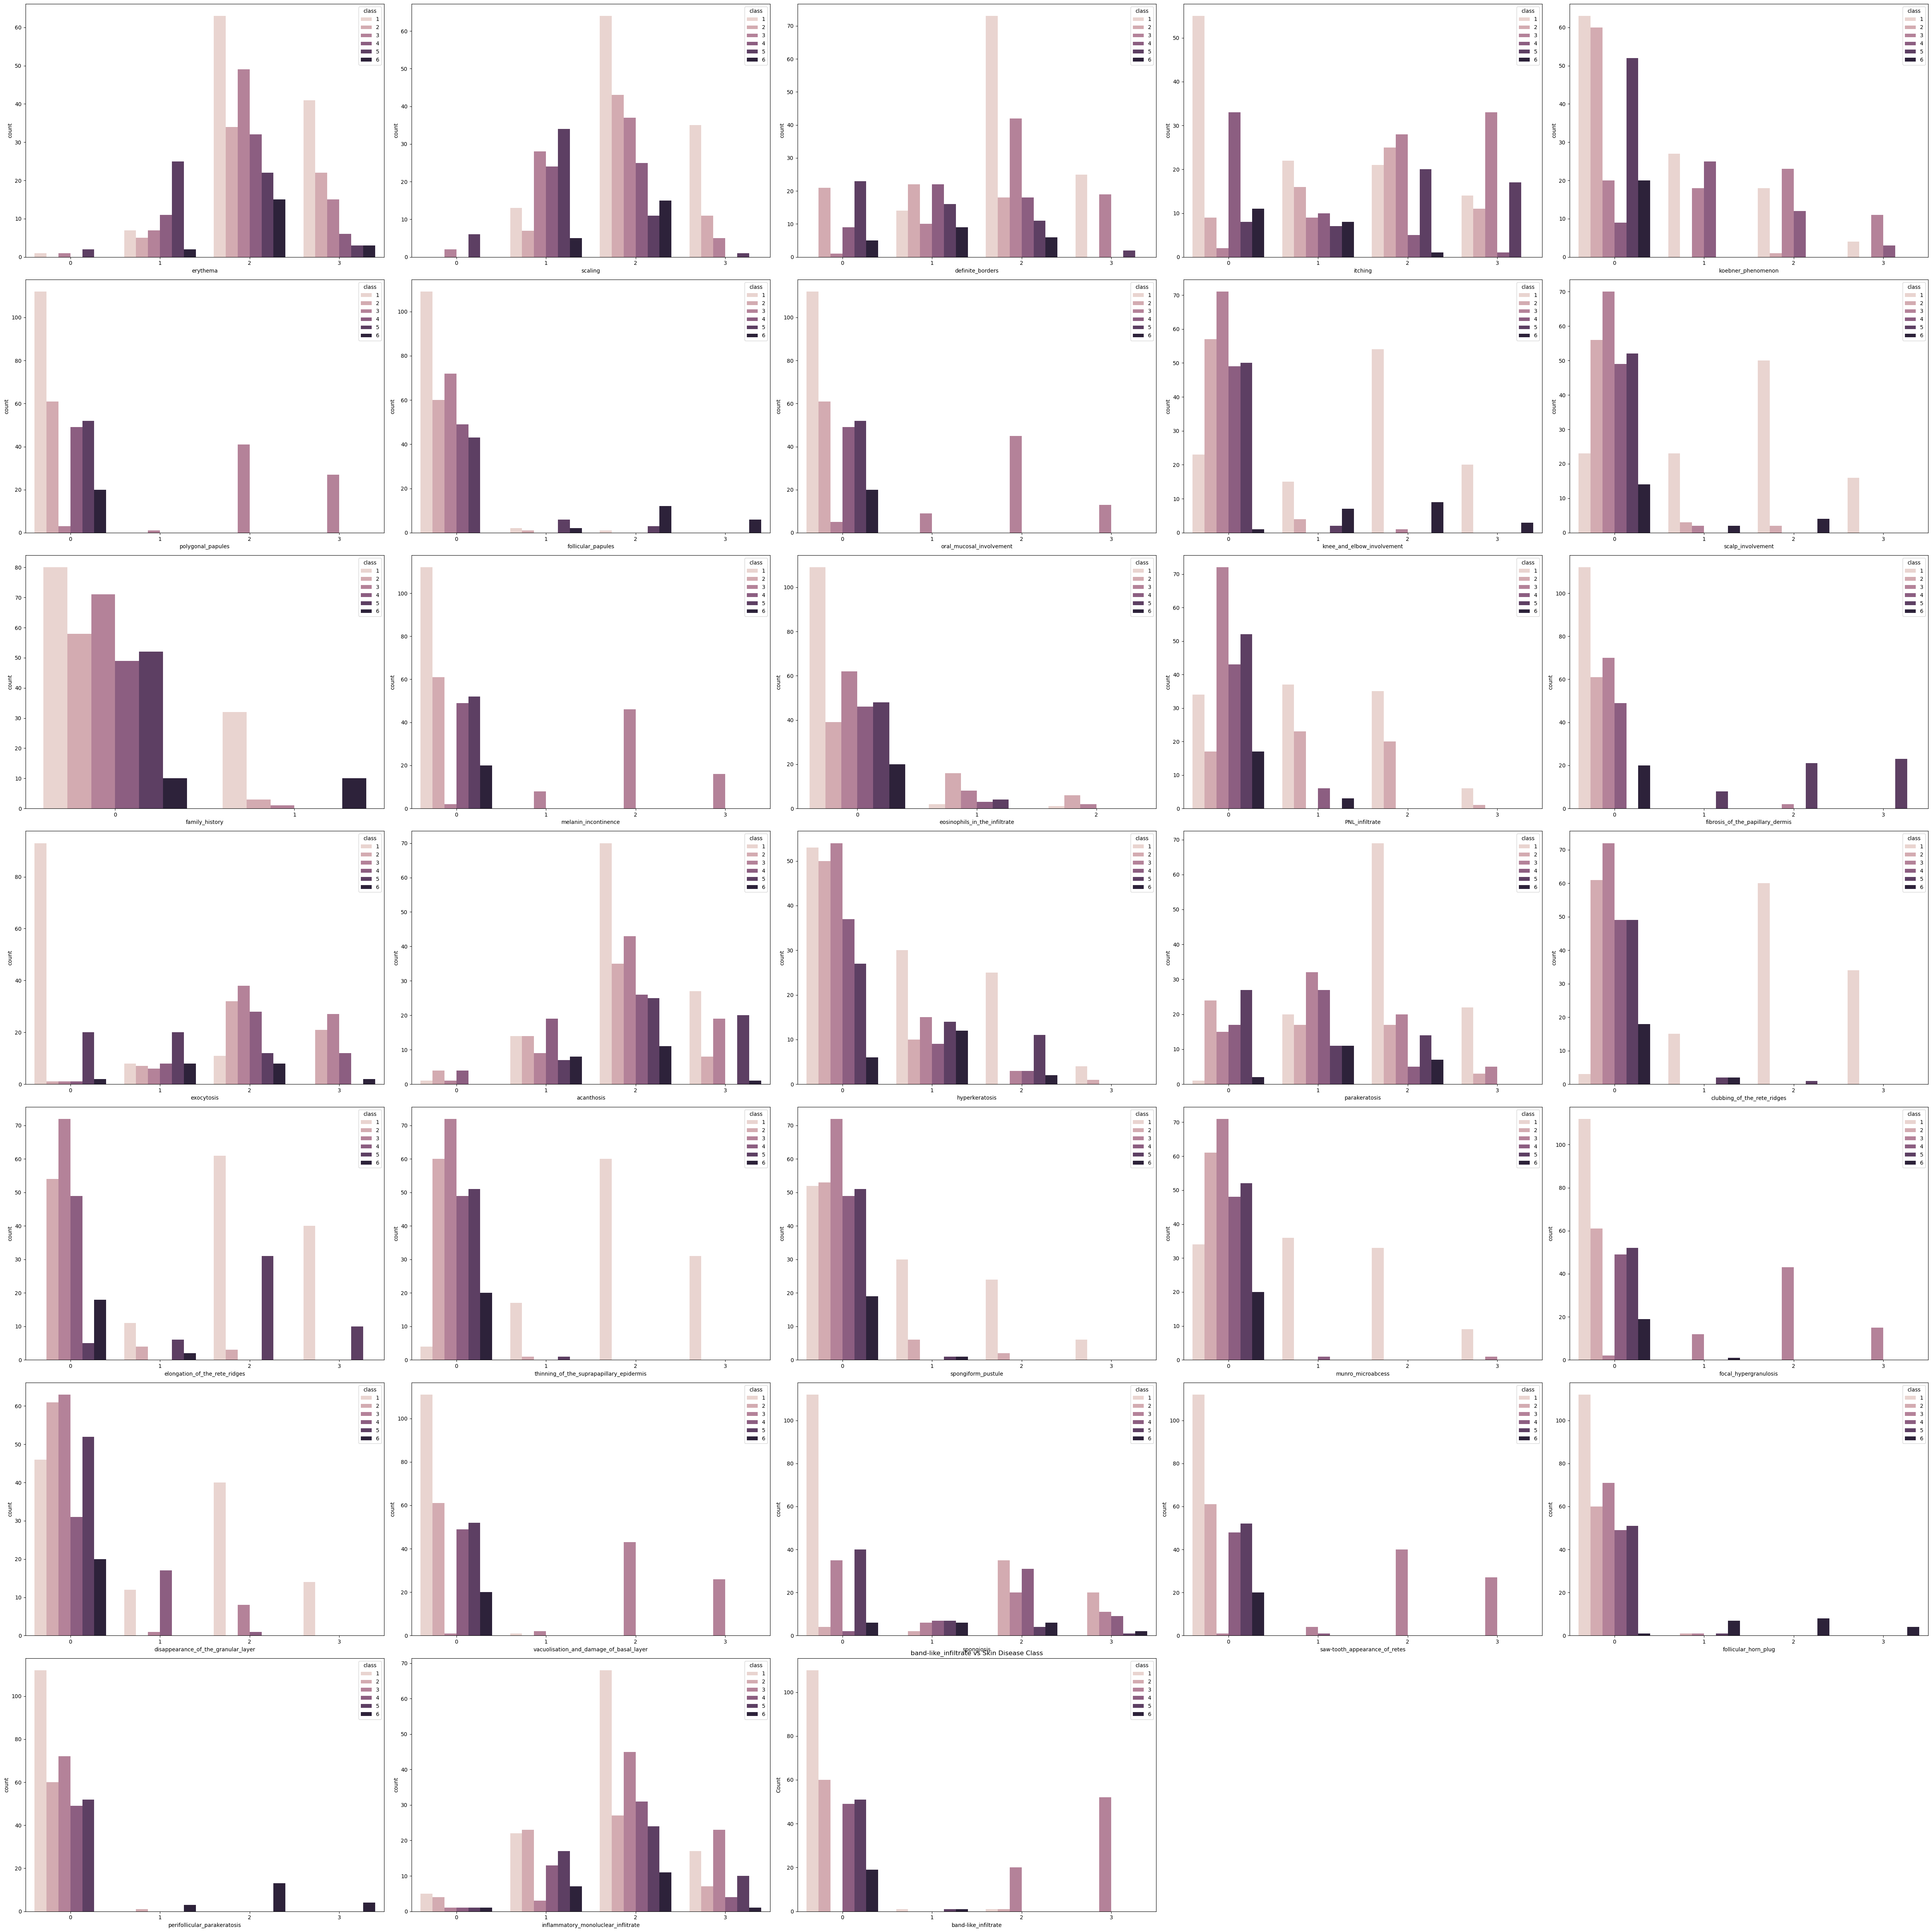

In [37]:
plt.figure(figsize=(50,50))  # Set figure size
num = 1  # Initialize subplot position
for col in feature_cols:  # Loop through feature columns
    plt.subplot(7,5,num)  # Create subplot
    sns.countplot(data=df, x=col, hue="class")  # Compare features across disease classes
    num = num + 1  # Move to next subplot
plt.tight_layout()  # Adjust subplot spacing
plt.title(f"{col} vs Skin Disease Class")  # Set plot title
plt.xlabel(col)  # Label x-axis
plt.ylabel("Count")  # Label y-axis
plt.show()  # Display all plots

### Insight: 
* Compares each feature across skin disease classes to identify patterns and symptoms that may help distinguish between diseases.

In [38]:
feature_class_mean = df.groupby("class")[feature_cols].mean()  # Calculate average feature values for each class

feature_class_mean  # Display class-wise feature averages

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate
class,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,2.285714,2.196429,2.098214,0.946429,0.669643,0.000000,0.035714,0.000000,1.633929,1.526786,0.285714,0.000000,0.035714,1.116071,0.000000,0.267857,2.098214,0.821429,2.000000,2.116071,2.258929,2.053571,0.857143,1.151786,0.000000,1.196429,0.008929,0.000000,0.000000,0.000000,0.000000,1.866071,0.026786
2,2.278689,2.065574,0.950820,1.622951,0.032787,0.000000,0.016393,0.000000,0.065574,0.114754,0.049180,0.000000,0.459016,1.081967,0.000000,2.196721,1.770492,0.213115,0.983607,0.000000,0.163934,0.016393,0.163934,0.000000,0.000000,0.000000,0.000000,2.163934,0.000000,0.016393,0.016393,1.606557,0.032787
3,2.083333,1.625000,2.097222,2.277778,1.347222,2.277778,0.000000,1.916667,0.027778,0.027778,0.013889,2.055556,0.166667,0.000000,0.055556,2.263889,2.111111,0.291667,1.208333,0.000000,0.000000,0.000000,0.000000,0.041667,1.986111,0.236111,2.305556,1.097222,2.291667,0.013889,0.000000,2.250000,2.722222
4,1.897959,1.510204,1.183673,0.469388,1.183673,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.061224,0.122449,0.000000,2.040816,1.448980,0.306122,0.755102,0.000000,0.000000,0.000000,0.000000,0.020408,0.000000,0.387755,0.000000,1.959184,0.020408,0.000000,0.000000,1.775510,0.000000
5,1.500000,1.134615,0.846154,1.884615,0.000000,0.000000,0.230769,0.000000,0.038462,0.000000,0.000000,0.000000,0.076923,0.000000,2.288462,0.846154,2.250000,0.692308,0.750000,0.076923,1.884615,0.019231,0.019231,0.000000,0.000000,0.000000,0.000000,0.346154,0.000000,0.019231,0.000000,1.826923,0.019231
6,2.050000,1.750000,1.050000,0.500000,0.000000,0.000000,2.200000,0.000000,1.700000,0.500000,0.500000,0.000000,0.000000,0.150000,0.000000,1.500000,1.650000,0.800000,1.250000,0.100000,0.100000,0.000000,0.050000,0.000000,0.050000,0.000000,0.000000,1.200000,0.000000,1.750000,2.050000,1.600000,0.050000


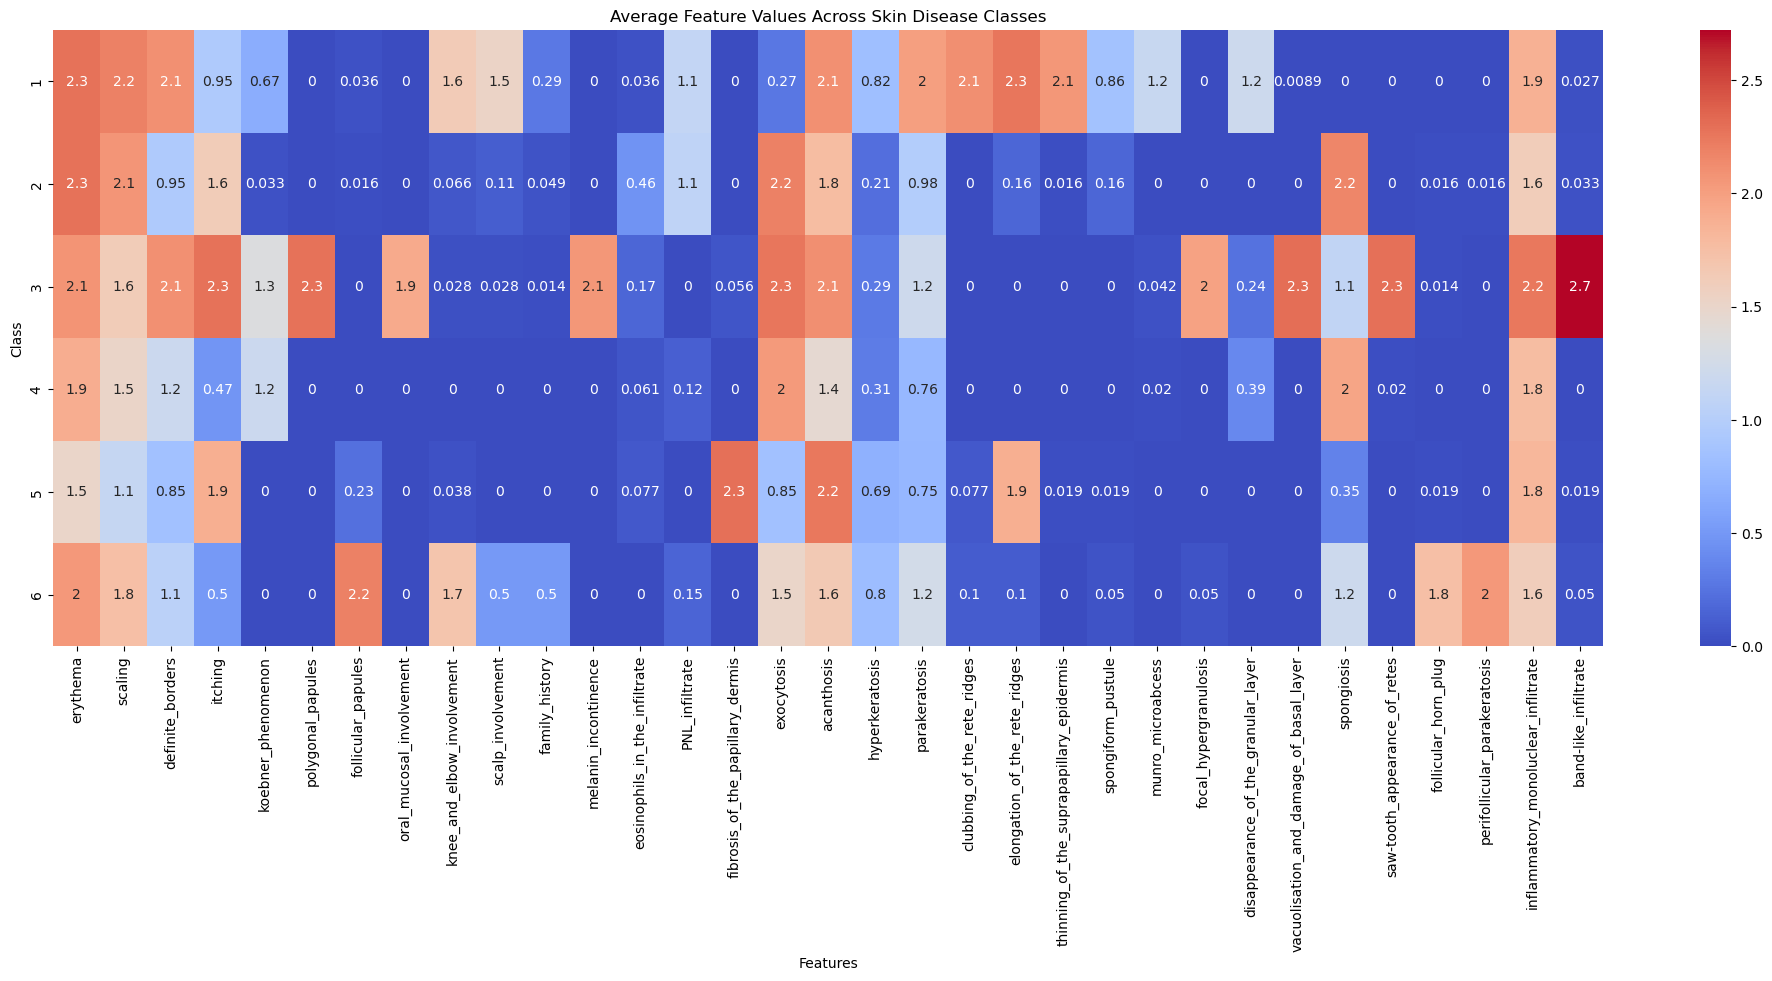

In [39]:
plt.figure(figsize=(25,8))  # Set figure size
sns.heatmap(feature_class_mean, annot=True, cmap="coolwarm")  # Display average feature values
plt.title("Average Feature Values Across Skin Disease Classes")  # Set plot title
plt.xlabel("Features")  # Label x-axis
plt.ylabel("Class")  # Label y-axis
plt.show()  # Display heatmap

### Insight: 
* Compares average feature values across skin disease classes to identify patterns and symptoms that may help distinguish between diseases.

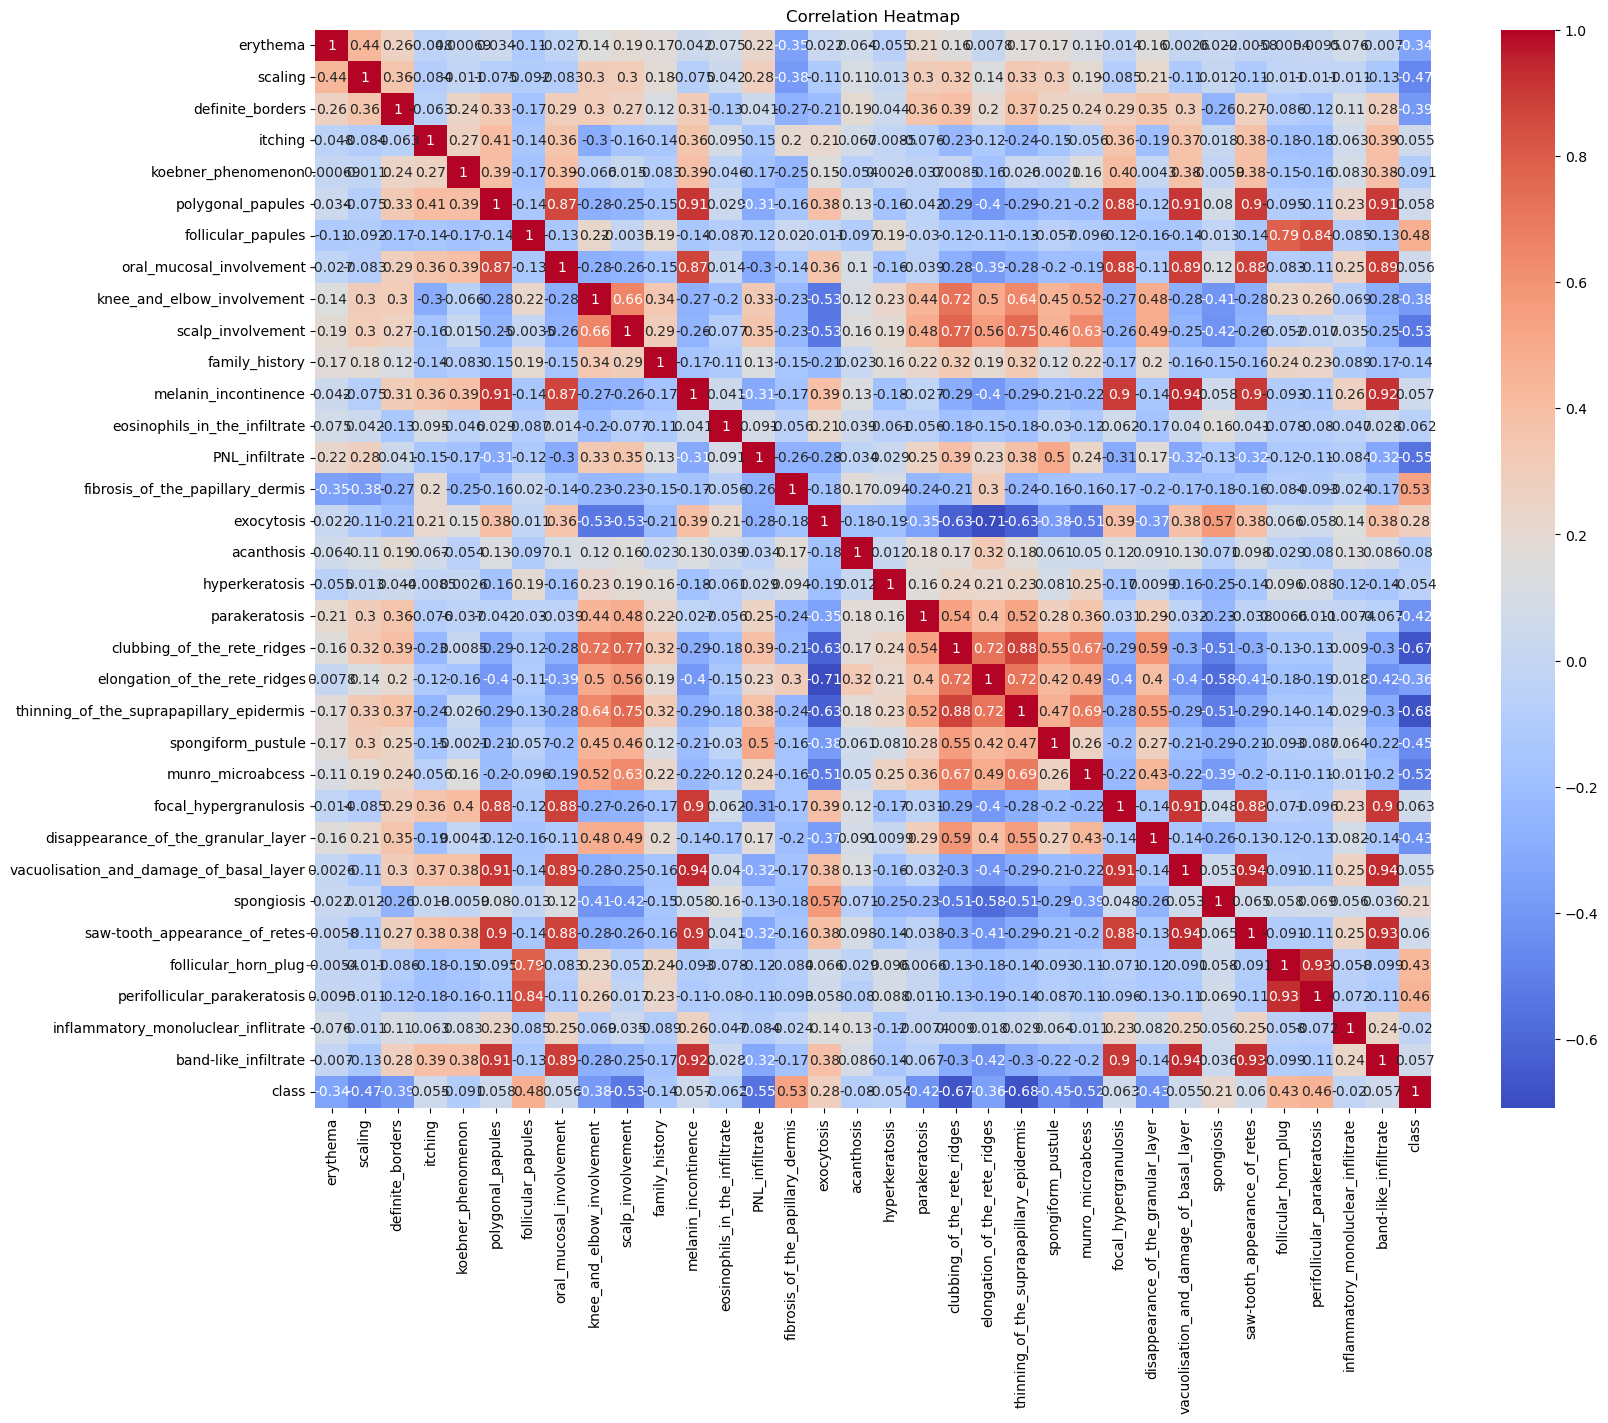

In [40]:
plt.figure(figsize=(18,14))  # Set figure size
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")  # Show feature correlations
plt.title("Correlation Heatmap")  # Set plot title
plt.show()  # Display heatmap

### Insight: 
* Shows correlations between numerical features to identify relationships and highly correlated features.

# Feature Engineering


### 1) DATA PREPROCESSING

In [41]:
for col in df.columns:  # Loop through all columns
    print(col, ":", sorted(df[col].unique()))  # Print sorted unique values

erythema : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
scaling : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
definite_borders : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
itching : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
koebner_phenomenon : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
polygonal_papules : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
follicular_papules : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
oral_mucosal_involvement : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
knee_and_elbow_involvement : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
scalp_involvement : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
family_history : [np.int64(0), np.int64(1)]
melanin_incontinence : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
eosinophils_in_the_infiltrate : [np.int64(0), np.int64(1), np.int64(2)]
PNL_infiltrate : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
fibrosis_of_the_papi

In [42]:
df.dtypes  # Display data types of all columns

erythema                                     int64
scaling                                      int64
definite_borders                             int64
itching                                      int64
koebner_phenomenon                           int64
polygonal_papules                            int64
follicular_papules                           int64
oral_mucosal_involvement                     int64
knee_and_elbow_involvement                   int64
scalp_involvement                            int64
family_history                               int64
melanin_incontinence                         int64
eosinophils_in_the_infiltrate                int64
PNL_infiltrate                               int64
fibrosis_of_the_papillary_dermis             int64
exocytosis                                   int64
acanthosis                                   int64
hyperkeratosis                               int64
parakeratosis                                int64
clubbing_of_the_rete_ridges    

In [43]:
df.loc[df["Age"]=="?","Age"]# finding invalid value using .loc

33     ?
34     ?
35     ?
36     ?
262    ?
263    ?
264    ?
265    ?
Name: Age, dtype: object

In [44]:
df.Age.value_counts() #checking how many time value repeated

Age
40    17
50    17
36    16
27    16
22    15
      ..
58     1
49     1
63     1
68     1
75     1
Name: count, Length: 61, dtype: int64

In [45]:
df.loc[df["Age"]=="?","Age"]=36 # using median replace valid value 

In [46]:
df.Age = df.Age.astype(int)  # change datatype 

In [47]:
df.Age.dtype  # Check the data type of the Age column

dtype('int64')

In [48]:
df.loc[df["Age"] < 11]  # Display rows where age is below 11

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
1,3,3,3,2,1,0,0,0,1,1,1,0,0,1,0,1,2,0,2,2,2,2,2,1,0,0,0,0,0,0,0,1,0,8,1
13,2,3,3,0,0,0,0,0,1,1,1,0,0,1,0,0,2,1,2,1,2,3,0,2,0,0,0,0,0,0,0,2,0,10,1
20,2,1,1,2,0,0,3,0,1,2,0,0,0,1,0,0,1,2,2,0,1,0,1,0,0,0,0,0,0,1,2,1,0,8,6
26,1,1,0,1,0,0,3,0,1,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,1,0,0,1,0,2,2,1,0,10,6
31,3,2,0,2,0,0,0,0,0,0,0,0,1,2,0,2,1,1,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,10,2
60,2,2,1,1,0,0,1,0,1,1,1,0,0,0,0,1,2,1,1,1,1,0,0,0,0,0,0,1,0,1,1,1,0,8,6
83,3,2,2,1,0,0,0,0,0,0,0,0,0,1,0,2,1,0,2,0,0,0,0,0,0,0,0,2,0,0,0,2,0,10,2
119,1,1,1,1,1,0,0,0,2,2,0,0,0,2,0,0,2,1,1,2,2,1,0,2,0,0,0,0,0,0,0,0,2,0,1
122,1,1,2,0,0,0,3,0,3,0,1,0,0,0,0,2,1,1,1,1,0,0,0,0,0,0,0,0,0,2,2,2,0,7,6
126,2,2,2,0,0,0,2,0,2,0,0,0,0,0,0,2,2,2,2,0,0,0,0,0,0,0,0,0,0,2,2,2,0,8,6


In [49]:
X = df.drop("class", axis=1)  # Select input features
y = df["class"]  # Select target variable

In [50]:
id_columns = ["id", "patient_id"]  # Define ID columns

for col in id_columns:  # Check each ID column
    if col in df.columns:  # Check if column exists
        print(col)  # Print column name

In [51]:
duplicate_columns = []  # Store duplicate columns

for i in range(len(df.columns)):  # Loop through columns
    for j in range(i + 1, len(df.columns)):  # Compare column pairs
        if df[df.columns[i]].equals(df[df.columns[j]]):  # Check identical values
            duplicate_columns.append((df.columns[i], df.columns[j]))  # Store duplicate pair

duplicate_columns  # Display duplicate columns

[]

In [52]:
constant_features = [col for col in df.columns if df[col].nunique() <= 1]  # Find columns with only one unique value

constant_features  # Display constant features

[]

In [53]:
df.isnull().sum().sum()  # Count total missing values in the dataset

np.int64(0)

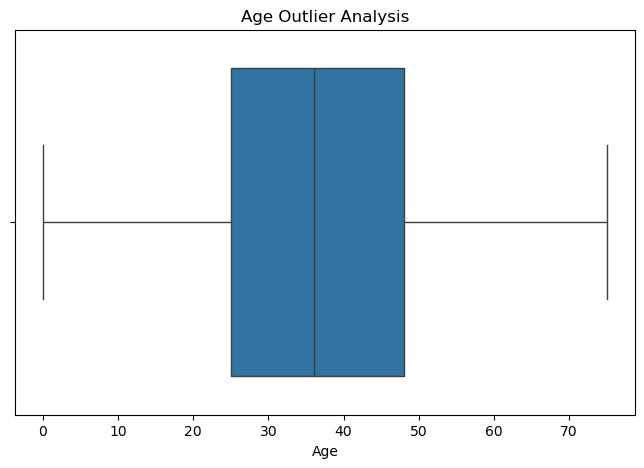

In [54]:
plt.figure(figsize=(8,5))  # Set figure size
sns.boxplot(x=df["Age"])  # Identify potential age outliers
plt.title("Age Outlier Analysis")  # Set plot title
plt.show()  # Display boxplot

### Insight: 
* Identifies potential outliers in the Age column by showing the median, spread, and unusually low or high age values.

In [55]:
print("X shape:", X.shape)  # Display input features dimensions
print("y shape:", y.shape)  # Display target variable dimensions

X shape: (366, 34)
y shape: (366,)


In [56]:
X.head()  # Display the first five rows of input features

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age
0,2,2,0,3,0,0,0,0,1,0,0,0,0,0,0,3,2,0,0,0,0,0,0,0,0,0,0,3,0,0,0,1,0,55
1,3,3,3,2,1,0,0,0,1,1,1,0,0,1,0,1,2,0,2,2,2,2,2,1,0,0,0,0,0,0,0,1,0,8
2,2,1,2,3,1,3,0,3,0,0,0,1,0,0,0,1,2,0,2,0,0,0,0,0,2,0,2,3,2,0,0,2,3,26
3,2,2,2,0,0,0,0,0,3,2,0,0,0,3,0,0,2,0,3,2,2,2,2,0,0,3,0,0,0,0,0,3,0,40
4,2,3,2,2,2,2,0,2,0,0,0,1,0,0,0,1,2,0,0,0,0,0,0,0,2,2,3,2,3,0,0,2,3,45


In [57]:
y.head()  # Display the first five target values

0    2
1    1
2    3
3    1
4    3
Name: class, dtype: int64

### 2) Train-Test Split 

In [58]:
from sklearn.model_selection import train_test_split  # Import function to split data into training and testing sets

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)  # Split data into 80% training and 20% testing sets

In [60]:
print("X_train:", X_train.shape)  # Display training features shape
print("X_test :", X_test.shape)  # Display testing features shape
print("y_train:", y_train.shape)  # Display training target shape
print("y_test :", y_test.shape)  # Display testing target shape

X_train: (292, 34)
X_test : (74, 34)
y_train: (292,)
y_test : (74,)


In [61]:
print(y_train.value_counts().sort_index())  # Count samples in each training class
print(y_train.value_counts(normalize=True).sort_index() * 100)  # Display class percentages

class
1    89
2    49
3    57
4    39
5    42
6    16
Name: count, dtype: int64
class
1    30.479452
2    16.780822
3    19.520548
4    13.356164
5    14.383562
6     5.479452
Name: proportion, dtype: float64


In [62]:
print(y_test.value_counts().sort_index())  # Count samples in each testing class
print(y_test.value_counts(normalize=True).sort_index() * 100)  # Display class percentages

class
1    23
2    12
3    15
4    10
5    10
6     4
Name: count, dtype: int64
class
1    31.081081
2    16.216216
3    20.270270
4    13.513514
5    13.513514
6     5.405405
Name: proportion, dtype: float64


### 3) Converting Balancing Data

In [63]:
from imblearn.over_sampling import SMOTE  # Import SMOTE to balance class distribution

In [64]:
smote = SMOTE(random_state=42)  # Initialize SMOTE

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)  # Balance training data

In [65]:
print("Before SMOTE:")  # Display heading
print(y_train.value_counts().sort_index())  # Show class counts before SMOTE

Before SMOTE:
class
1    89
2    49
3    57
4    39
5    42
6    16
Name: count, dtype: int64


In [66]:
print("After SMOTE:")  # Display heading
print(y_train_smote.value_counts().sort_index())  # Show class counts after SMOTE

After SMOTE:
class
1    89
2    89
3    89
4    89
5    89
6    89
Name: count, dtype: int64


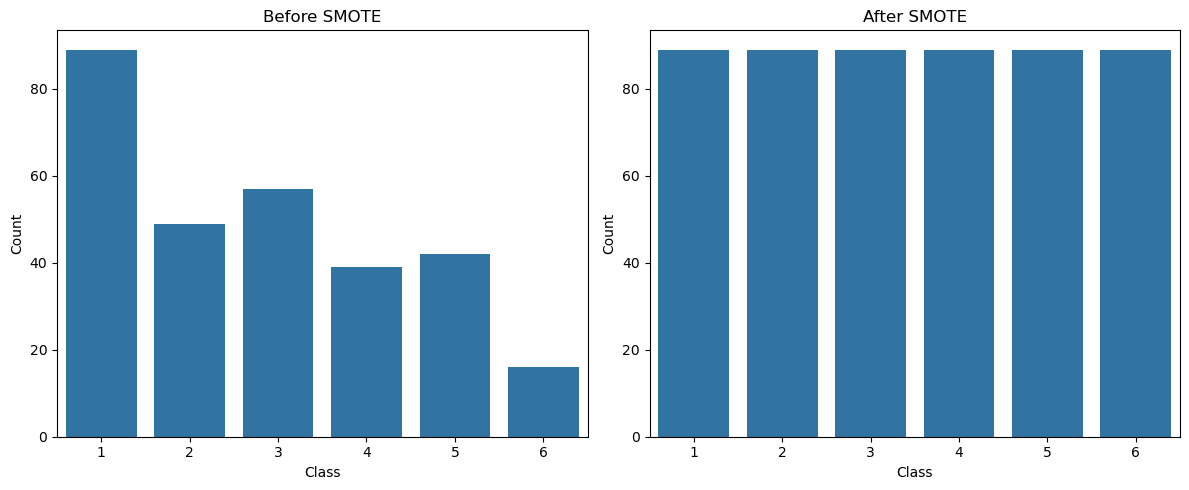

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))  # Create two side-by-side plots

sns.countplot(x=y_train, ax=axes[0])  # Plot class counts before SMOTE
axes[0].set_title("Before SMOTE")  # Set first plot title
axes[0].set_xlabel("Class")  # Label x-axis
axes[0].set_ylabel("Count")  # Label y-axis

sns.countplot(x=y_train_smote, ax=axes[1])  # Plot class counts after SMOTE
axes[1].set_title("After SMOTE")  # Set second plot title
axes[1].set_xlabel("Class")  # Label x-axis
axes[1].set_ylabel("Count")  # Label y-axis

plt.tight_layout()  # Adjust plot spacing
plt.show()  # Display both plots

### Insight: 
* SMOTE balances the training dataset by increasing minority-class samples, helping reduce class imbalance.

### 4) Standardization of Features using StandardScaler

In [68]:
from sklearn.preprocessing import StandardScaler  # Import feature scaling tool

scaler = StandardScaler()  # Initialize the scaler

In [69]:
X_train_scaled = scaler.fit_transform(X_train_smote)  # Fit scaler and standardize training data
X_test_scaled = scaler.transform(X_test)  # Standardize testing data using the same scaler

In [70]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)  # Convert scaled training data into DataFrame

X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)  # Convert scaled testing data into DataFrame

In [71]:
print("Training data shape:", X_train_scaled.shape)  # Display scaled training data dimensions
print("Testing data shape :", X_test_scaled.shape)  # Display scaled testing data dimensions
print("Training target shape:", y_train_smote.shape)  # Display training target dimensions
print("Testing target shape :", y_test.shape)  # Display testing target dimensions

Training data shape: (534, 34)
Testing data shape : (74, 34)
Training target shape: (534,)
Testing target shape : (74,)


### 5) Feature Selection

In [72]:
constant_features = [col for col in X_train_smote.columns if X_train_smote[col].nunique() <= 1]  # Find constant features

print("Constant Features:", constant_features)  # Display constant features

Constant Features: []


In [73]:
X_train_smote = X_train_smote.drop(columns=constant_features)  # Remove constant features from training data
X_test_scaled = X_test_scaled.drop(columns=constant_features)  # Remove constant features from testing data

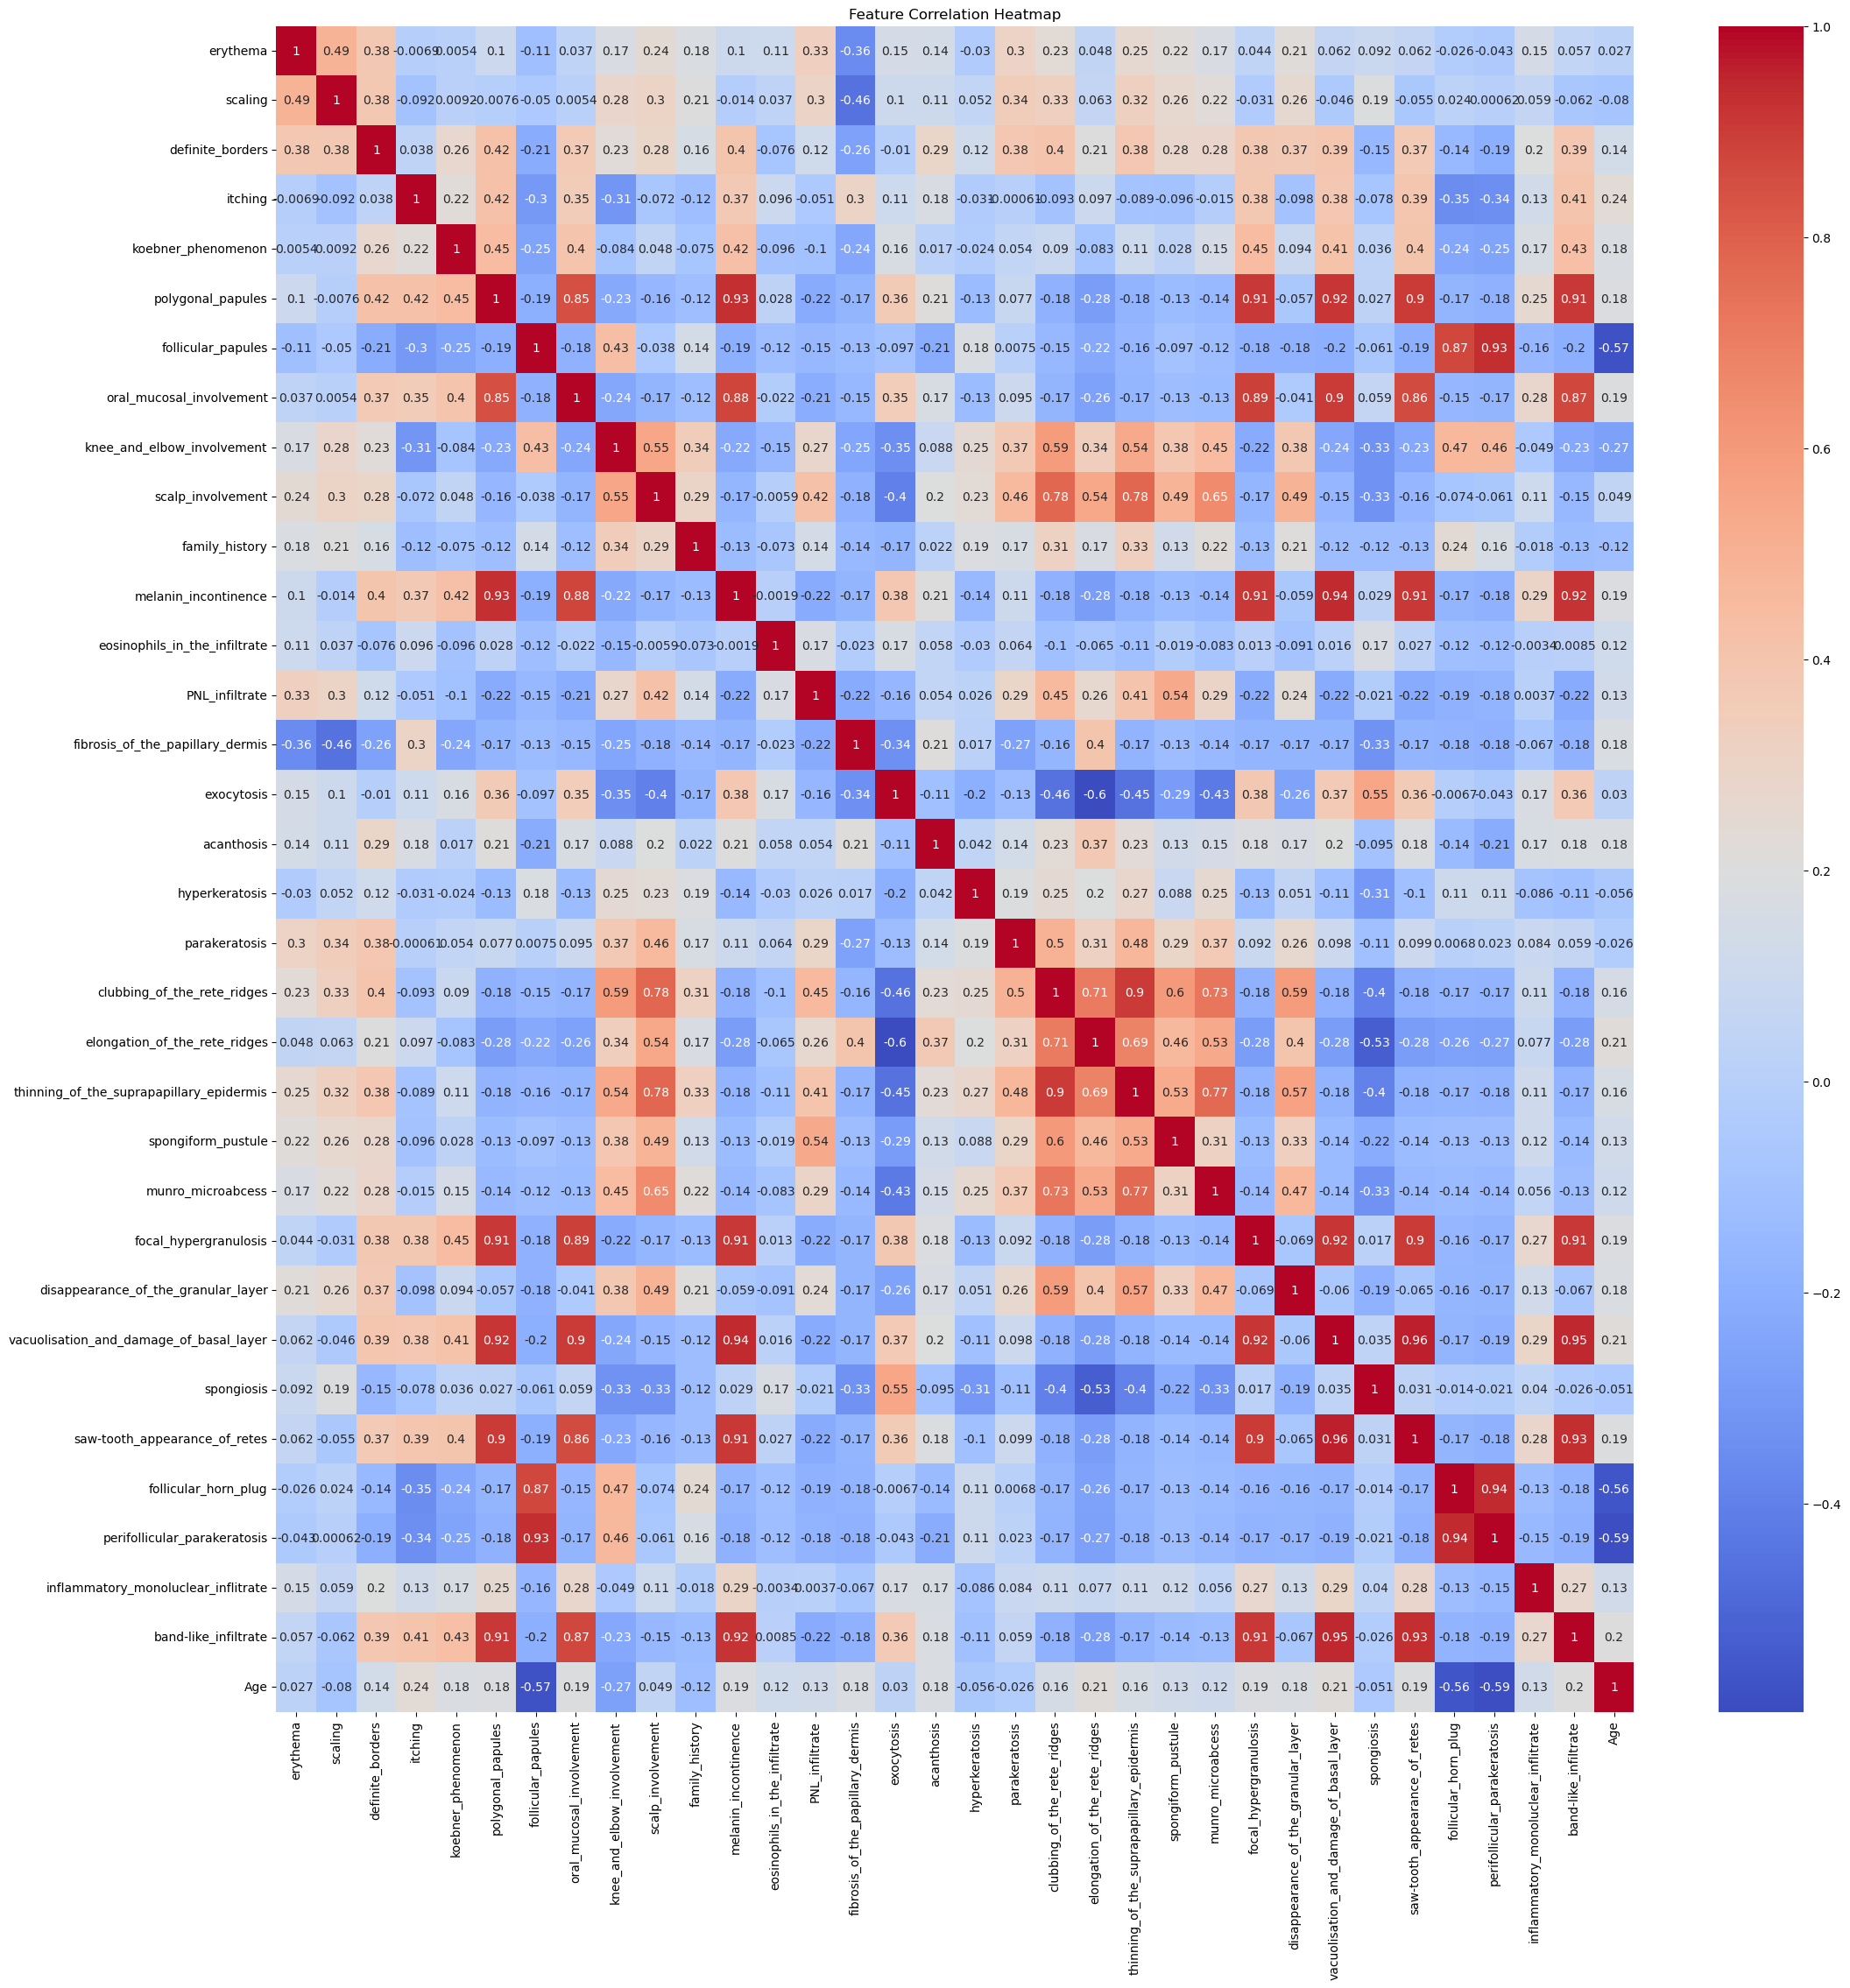

In [74]:
plt.figure(figsize=(25,25))  # Set figure size
sns.heatmap(X_train_smote.corr(), annot=True, cmap="coolwarm")  # Plot feature correlations
plt.title("Feature Correlation Heatmap")  # Set plot title
plt.show()  # Display heatmap

### Insight: 
* Identifies highly correlated features in the training data to help detect redundant features.

In [75]:
corr_matrix = X_train_smote.corr().abs()  # Calculate absolute correlation values

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))  # Select upper triangle

high_corr = [column for column in upper.columns if any(upper[column] > 0.90)]  # Find features correlated above 90%

print("Highly Correlated Features:")  # Display heading
print(high_corr)  # Print highly correlated features

Highly Correlated Features:
['melanin_incontinence', 'thinning_of_the_suprapapillary_epidermis', 'focal_hypergranulosis', 'vacuolisation_and_damage_of_basal_layer', 'saw-tooth_appearance_of_retes', 'perifollicular_parakeratosis', 'band-like_infiltrate']


In [76]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif  # Import feature selection tools

selector = SelectKBest(score_func=mutual_info_classif, k="all")  # Initialize feature selector

selector.fit(X_train_smote, y_train_smote)  # Calculate feature importance scores

,score_func,<function mut...0020F3E1C4D60>
,k,'all'


In [77]:
feature_scores = pd.DataFrame({  # Create feature score DataFrame
    "Feature": X_train_smote.columns,  # Store feature names
    "Score": selector.scores_  # Store feature importance scores
})

feature_scores = feature_scores.sort_values(by="Score", ascending=False)  # Sort scores in descending order

feature_scores  # Display feature scores

,Feature,Score
20,elongation_of_the_rete_ridges,0.530271
33,Age,0.502706
24,focal_hypergranulosis,0.467984
8,knee_and_elbow_involvement,0.462318
14,fibrosis_of_the_papillary_dermis,0.458575
30,perifollicular_parakeratosis,0.455594
29,follicular_horn_plug,0.455212
11,melanin_incontinence,0.452269
32,band-like_infiltrate,0.451298
5,polygonal_papules,0.447408


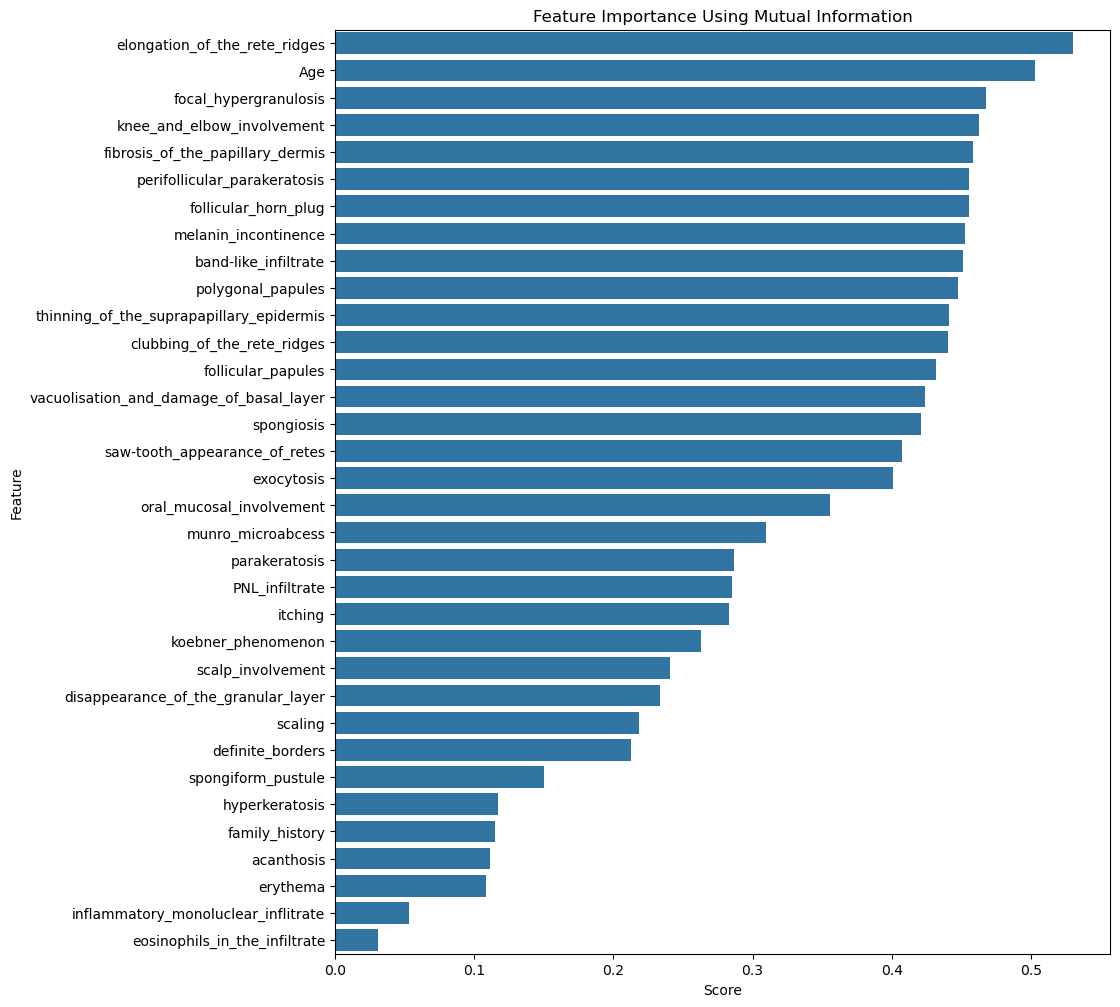

In [78]:
plt.figure(figsize=(10,12))  # Set figure size
sns.barplot(data=feature_scores, x="Score", y="Feature")  # Plot feature scores
plt.title("Feature Importance Using Mutual Information")  # Set plot title
plt.show()  # Display graph

In [79]:
top_features = feature_scores.head(20)["Feature"].tolist()  # Select top 20 features

print("Top Features:")  # Display heading
print(top_features)  # Print selected features

Top Features:
['elongation_of_the_rete_ridges', 'Age', 'focal_hypergranulosis', 'knee_and_elbow_involvement', 'fibrosis_of_the_papillary_dermis', 'perifollicular_parakeratosis', 'follicular_horn_plug', 'melanin_incontinence', 'band-like_infiltrate', 'polygonal_papules', 'thinning_of_the_suprapapillary_epidermis', 'clubbing_of_the_rete_ridges', 'follicular_papules', 'vacuolisation_and_damage_of_basal_layer', 'spongiosis', 'saw-tooth_appearance_of_retes', 'exocytosis', 'oral_mucosal_involvement', 'munro_microabcess', 'parakeratosis']


In [80]:
X_train_selected = X_train_smote[top_features]  # Select top features from training data
X_test_selected = X_test_scaled[top_features]  # Select top features from testing data

print("Selected Training Shape:", X_train_selected.shape)  # Display training shape
print("Selected Testing Shape :", X_test_selected.shape)  # Display testing shape

Selected Training Shape: (534, 20)
Selected Testing Shape : (74, 20)


# Model Selection

### Logistic Regression

In [81]:
from sklearn.linear_model import LogisticRegression  # Import Logistic Regression model

In [82]:
lr_model = LogisticRegression()  # Initialize Logistic Regression model

In [83]:
lr_model.fit(X_train_selected, y_train_smote)  # Train Logistic Regression model
print("Logistic Regression Model Created Successfully")  # Display success message

Logistic Regression Model Created Successfully


In [84]:
y_pred_lr = lr_model.predict(X_test_selected)  # Predict skin disorder classes for test data
y_pred_lr  # Display predicted results

array([4, 3, 4, 1, 4, 3, 4, 1, 4, 3, 1, 5, 5, 3, 5, 6, 6, 1, 5, 3, 1, 4,
       1, 1, 4, 3, 4, 1, 6, 4, 4, 5, 4, 4, 3, 1, 3, 5, 1, 1, 4, 1, 4, 1,
       1, 4, 1, 1, 3, 5, 1, 1, 1, 4, 3, 3, 1, 6, 4, 1, 1, 3, 5, 5, 4, 3,
       3, 4, 1, 3, 4, 4, 4, 5])

### Model Evulation 

In [85]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report  # Import classification evaluation metrics

In [86]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)  # Calculate Logistic Regression accuracy

In [87]:
lr_precision = precision_score(y_test, y_pred_lr, average="weighted")  # Calculate weighted precision

In [88]:
lr_recall = recall_score(y_test, y_pred_lr, average="weighted")  # Calculate weighted recall

In [89]:
lr_f1 = f1_score(y_test, y_pred_lr, average="weighted")  # Calculate weighted F1-score

In [90]:
print("Logistic Regression Model Evaluation Results")  # Display evaluation heading
print("-----------------")  # Print separator
print("Accuracy :", lr_accuracy)  # Display accuracy
print("Precision:", lr_precision)  # Display precision
print("Recall   :", lr_recall)  # Display recall
print("F1 Score :", lr_f1)  # Display F1-score

Logistic Regression Model Evaluation Results
-----------------
Accuracy : 0.8378378378378378
Precision: 0.7641277641277642
Recall   : 0.8378378378378378
F1 Score : 0.7871621621621622


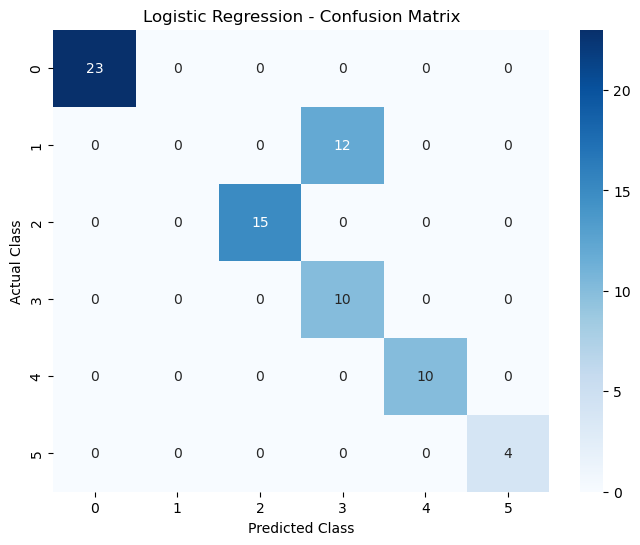

In [91]:
cm_lr = confusion_matrix(y_test, y_pred_lr)  # Create confusion matrix
cm_lr  # Display confusion matrix values

plt.figure(figsize=(8, 6))  # Set figure size

sns.heatmap(
    cm_lr,  # Provide confusion matrix data
    annot=True,  # Display values inside cells
    fmt="d",  # Show values as integers
    cmap="Blues"  # Set blue color palette
)

plt.title("Logistic Regression - Confusion Matrix")  # Add chart title
plt.xlabel("Predicted Class")  # Label x-axis
plt.ylabel("Actual Class")  # Label y-axis

plt.show()  # Display confusion matrix heatmap

### Hyper Parameter Tunning with Logistic Regression

In [92]:
from sklearn.model_selection import GridSearchCV  # Import GridSearchCV for hyperparameter tuning

In [93]:
lr_param_grid = {  # Define hyperparameter values for tuning
    "C": [0.01, 0.1, 1, 10, 100],  # Set regularization strength values
    "solver": ["lbfgs", "liblinear"]  # Set optimization algorithms
}

In [94]:
lr_grid = GridSearchCV(
    estimator=LogisticRegression(max_iter=2000, random_state=42),  # Set Logistic Regression model
    param_grid=lr_param_grid,  # Provide hyperparameter combinations
    cv=5,  # Use 5-fold cross-validation
    scoring="f1_weighted",  # Evaluate using weighted F1-score
    n_jobs=-1  # Use all available CPU cores
)
lr_grid  # Display GridSearchCV configuration

,estimator,LogisticRegre...ndom_state=42)
,param_grid,"{'C': [0.01, 0.1, ...], 'solver': ['lbfgs', 'liblinear']}"
,scoring,'f1_weighted'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [95]:
lr_grid.fit(X_train_selected, y_train_smote)  # Perform hyperparameter tuning using GridSearchCV
print("Logistic Regression Hyperparameter Tuning Completed")  # Display completion message

Logistic Regression Hyperparameter Tuning Completed


In [96]:
print("Best Parameters:")  # Display best hyperparameters
print(lr_grid.best_params_)  # Show the best parameter combination

print("Best Cross Validation F1 Score:")  # Display best cross-validation score
print(lr_grid.best_score_)  # Show the best weighted F1-score

Best Parameters:
{'C': 1, 'solver': 'liblinear'}
Best Cross Validation F1 Score:
0.8923881184838788


In [97]:
lr_tuned = lr_grid.best_estimator_  # Select the best-tuned Logistic Regression model
lr_tuned  # Display the tuned model

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'liblinear'
,max_iter,2000
,multi_class,'deprecated'


In [98]:
y_pred_lr_tuned = lr_tuned.predict(X_test_selected)  # Predict classes using the tuned model
y_pred_lr_tuned  # Display tuned predictions

array([4, 3, 4, 1, 4, 3, 4, 1, 4, 3, 1, 5, 5, 3, 5, 6, 6, 1, 5, 3, 1, 4,
       1, 1, 4, 3, 4, 1, 6, 4, 4, 5, 4, 4, 3, 1, 3, 5, 1, 1, 4, 1, 4, 1,
       1, 4, 1, 1, 3, 5, 1, 1, 1, 4, 3, 3, 1, 6, 4, 1, 1, 3, 5, 5, 4, 3,
       3, 4, 1, 3, 4, 4, 4, 5])

### Logistic Regression in Model Evulation with Hyper Parameter Tunning"

In [99]:
lr_tuned_accuracy = accuracy_score(y_test, y_pred_lr_tuned)  # Calculate tuned model accuracy

In [100]:
lr_tuned_precision = precision_score(y_test, y_pred_lr_tuned, average="weighted")  # Calculate tuned model precision

In [101]:
lr_tuned_recall = recall_score(y_test, y_pred_lr_tuned, average="weighted")  # Calculate tuned model recall

In [102]:
lr_tuned_f1 = f1_score(y_test, y_pred_lr_tuned, average="weighted")  # Calculate tuned model F1-score

In [103]:
print("Logistic Regression Model Evaluation with Hyperparameter Tuning Results")  # Display evaluation heading
print("-----------------")  # Print separator
print("Accuracy :", lr_tuned_accuracy)  # Display tuned accuracy
print("Precision:", lr_tuned_precision)  # Display tuned precision
print("Recall   :", lr_tuned_recall)  # Display tuned recall
print("F1 Score :", lr_tuned_f1)  # Display tuned F1-score

Logistic Regression Model Evaluation with Hyperparameter Tuning Results
-----------------
Accuracy : 0.8378378378378378
Precision: 0.7641277641277642
Recall   : 0.8378378378378378
F1 Score : 0.7871621621621622


In [104]:
Lr_tuned_CR = classification_report(y_test, y_pred_lr_tuned)  # Generate tuned model classification report
print(Lr_tuned_CR)  # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.00      0.00      0.00        12
           3       1.00      1.00      1.00        15
           4       0.45      1.00      0.62        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.84        74
   macro avg       0.74      0.83      0.77        74
weighted avg       0.76      0.84      0.79        74



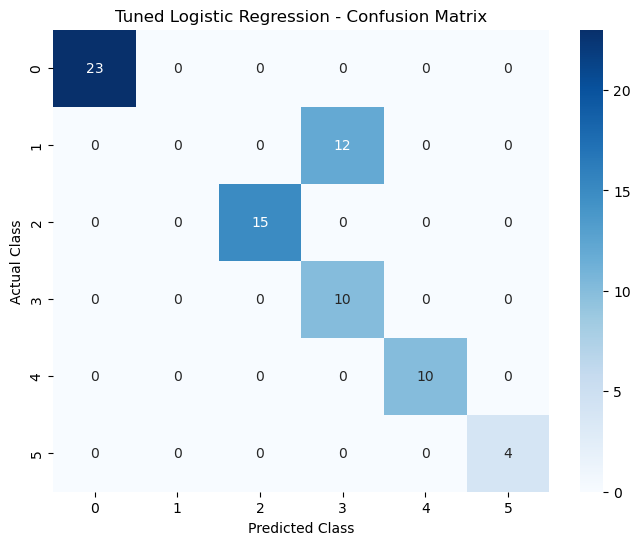

In [105]:
cm_lr_tuned = confusion_matrix(y_test, y_pred_lr_tuned)  # Create tuned model confusion matrix
plt.figure(figsize=(8, 6))  # Set figure size
sns.heatmap(cm_lr_tuned, annot=True, fmt="d", cmap="Blues")  # Plot confusion matrix heatmap
plt.title("Tuned Logistic Regression - Confusion Matrix")  # Add chart title
plt.xlabel("Predicted Class")  # Label x-axis
plt.ylabel("Actual Class")  # Label y-axis
plt.show()  # Display confusion matrix

### KNN

In [106]:
from sklearn.neighbors import KNeighborsClassifier  # Import KNN classification algorithm

In [107]:
knn_model = KNeighborsClassifier()  # Initialize KNN model

In [108]:
knn_model.fit(X_train_selected, y_train_smote)  # Train KNN model
print("KNN Model Created Successfully")  # Display success message

KNN Model Created Successfully


In [109]:
y_pred_knn = knn_model.predict(X_test_selected)  # Predict skin disorder classes using KNN
y_pred_knn  # Display predicted results

array([6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 1, 6, 6, 1, 6,
       1, 6, 6, 6, 6, 1, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 1, 6, 6, 6, 1,
       1, 6, 1, 6, 6, 6, 1, 6, 1, 6, 6, 6, 1, 6, 6, 6, 6, 6, 6, 6, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6])

### Model Evaluation

In [110]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)  # Calculate KNN model accuracy

In [111]:
knn_precision = precision_score(y_test, y_pred_knn, average="weighted")  # Calculate weighted KNN precision

In [112]:
knn_recall = recall_score(y_test, y_pred_knn, average="weighted")  # Calculate weighted KNN recall

In [113]:
knn_f1 = f1_score(y_test, y_pred_knn, average="weighted")  # Calculate weighted KNN F1-score

In [114]:
print("KNN Model Evaluation Results")  # Display evaluation heading
print("-----------------")  # Print separator
print("Accuracy :", knn_accuracy)  # Display accuracy
print("Precision:", knn_precision)  # Display precision
print("Recall   :", knn_recall)  # Display recall
print("F1 Score :", knn_f1)  # Display F1-score

KNN Model Evaluation Results
-----------------
Accuracy : 0.20270270270270271
Precision: 0.31424281424281425
Recall   : 0.20270270270270271
F1 Score : 0.2075670929929051


In [115]:
knn_cr = classification_report(y_test, y_pred_knn)  # Generate KNN classification report
print(knn_cr)  # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      0.48      0.65        23
           2       0.00      0.00      0.00        12
           3       0.00      0.00      0.00        15
           4       0.00      0.00      0.00        10
           5       0.00      0.00      0.00        10
           6       0.06      1.00      0.12         4

    accuracy                           0.20        74
   macro avg       0.18      0.25      0.13        74
weighted avg       0.31      0.20      0.21        74



### KNN with Hyperparameter Tuning

In [116]:
knn_param_grid = {  # Define KNN hyperparameter values
    "n_neighbors": [3, 5, 7, 9, 11],  # Set the number of neighbors
    "weights": ["uniform", "distance"],  # Set neighbor weighting methods
    "metric": ["euclidean", "manhattan"]  # Set distance calculation methods
}
knn_param_grid  # Display parameter grid

{'n_neighbors': [3, 5, 7, 9, 11],
 'weights': ['uniform', 'distance'],
 'metric': ['euclidean', 'manhattan']}

In [117]:
knn_grid = GridSearchCV(
    estimator=KNeighborsClassifier(),  # Set KNN model
    param_grid=knn_param_grid,  # Provide hyperparameter combinations
    cv=5,  # Use 5-fold cross-validation
    scoring="f1_weighted",  # Evaluate using weighted F1-score
    n_jobs=-1  # Use all available CPU cores
)
knn_grid  # Display GridSearchCV configuration

,estimator,KNeighborsClassifier()
,param_grid,"{'metric': ['euclidean', 'manhattan'], 'n_neighbors': [3, 5, ...], 'weights': ['uniform', 'distance']}"
,scoring,'f1_weighted'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_neighbors,5


In [118]:
knn_grid.fit(X_train_selected, y_train_smote)  # Perform KNN hyperparameter tuning
print("KNN Hyperparameter Tuning Completed")  # Display completion message

KNN Hyperparameter Tuning Completed


In [119]:
print("Best Parameters:")  # Display best hyperparameters
print(knn_grid.best_params_)  # Show the best parameter combination

print("Best Cross Validation F1 Score:")  # Display best cross-validation score
print(knn_grid.best_score_)  # Show the best weighted F1-score

Best Parameters:
{'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}
Best Cross Validation F1 Score:
0.9104881833976194


In [120]:
knn_tuned = knn_grid.best_estimator_  # Select the best-tuned KNN model
knn_tuned  # Display the tuned model

,n_neighbors,5
,weights,'distance'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'manhattan'
,metric_params,None
,n_jobs,None


In [121]:
y_pred_knn_tuned = knn_tuned.predict(X_test_selected)  # Predict classes using the tuned KNN model
y_pred_knn_tuned  # Display tuned KNN predictions

array([6, 3, 6, 1, 6, 3, 6, 1, 6, 3, 1, 6, 6, 3, 6, 6, 6, 1, 6, 3, 1, 6,
       1, 1, 6, 6, 6, 1, 6, 6, 6, 6, 6, 6, 3, 1, 6, 6, 1, 1, 6, 1, 6, 1,
       1, 6, 1, 1, 6, 6, 1, 1, 1, 6, 2, 6, 1, 6, 6, 1, 1, 3, 6, 6, 6, 6,
       3, 6, 1, 3, 6, 6, 6, 6])

### Model Evulation

In [122]:
knn_tuned_accuracy = accuracy_score(y_test, y_pred_knn_tuned)  # Calculate tuned KNN model accuracy

In [123]:
knn_tuned_precision = precision_score(y_test, y_pred_knn_tuned, average="weighted")# Calculate weighted precision for the tuned KNN model

In [124]:
knn_tuned_recall = recall_score(y_test, y_pred_knn_tuned, average="weighted")  # Calculate weighted recall for the tuned KNN model

In [125]:
knn_tuned_f1 = f1_score(y_test, y_pred_knn_tuned, average="weighted")# Calculate weighted F1-score for the tuned KNN model

In [126]:
print("KNN Model Evaluation with Hyperparameter Tuning Results")  # Display evaluation heading
print("-----------------")  # Print separator
print("Accuracy :", knn_tuned_accuracy)  # Display tuned accuracy
print("Precision:", knn_tuned_precision)  # Display tuned precision
print("Recall   :", knn_tuned_recall)  # Display tuned recall
print("F1 Score :", knn_tuned_f1)  # Display tuned F1-score

KNN Model Evaluation with Hyperparameter Tuning Results
-----------------
Accuracy : 0.4864864864864865
Precision: 0.5187870797626896
Recall   : 0.4864864864864865
F1 Score : 0.47244744744744743


In [127]:
knn_tunned_CR = classification_report(y_test, y_pred_knn_tuned)# Generate classification report for the tuned KNN model
print(knn_tunned_CR)  # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.00      0.00      0.00        12
           3       1.00      0.60      0.75        15
           4       0.00      0.00      0.00        10
           5       0.00      0.00      0.00        10
           6       0.10      1.00      0.18         4

    accuracy                           0.49        74
   macro avg       0.35      0.43      0.32        74
weighted avg       0.52      0.49      0.47        74



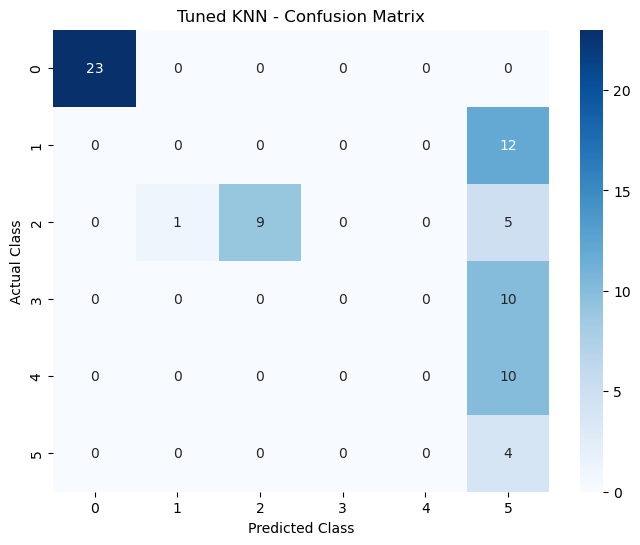

In [128]:
cm_knn = confusion_matrix(y_test, y_pred_knn_tuned)  # Create confusion matrix for tuned KNN model

plt.figure(figsize=(8, 6))  # Set figure size

sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues")  # Display confusion matrix as a heatmap
plt.title("Tuned KNN - Confusion Matrix")  # Add chart title
plt.xlabel("Predicted Class")  # Label x-axis
plt.ylabel("Actual Class")  # Label y-axis

plt.show()  # Display the confusion matrix

### Decision Tree

In [129]:
from sklearn.tree import DecisionTreeClassifier  # Import Decision Tree classification algorithm

In [130]:
dt_model = DecisionTreeClassifier(random_state=42)  # Initialize Decision Tree model with a fixed random state for reproducible results

In [131]:
dt_model.fit(X_train_selected, y_train_smote)  # Train the Decision Tree model using training data
print("Decision Tree Model Created Successfully")  # Display success message

Decision Tree Model Created Successfully


In [132]:
y_pred_dt = dt_model.predict(X_test_selected)  # Predict skin disorder classes using the Decision Tree model
y_pred_dt  # Display predicted results

array([4, 3, 4, 4, 4, 3, 4, 1, 2, 1, 1, 5, 5, 3, 5, 6, 6, 1, 5, 3, 1, 4,
       1, 1, 4, 3, 4, 1, 6, 4, 4, 5, 6, 2, 3, 1, 1, 5, 1, 1, 4, 1, 4, 1,
       1, 4, 1, 1, 5, 5, 1, 1, 1, 4, 3, 3, 1, 6, 4, 1, 1, 3, 5, 5, 4, 3,
       3, 4, 4, 3, 4, 4, 4, 5])

### Model Evulation:

In [133]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)  # Calculate Decision Tree model accuracy

In [134]:
dt_precision = precision_score(y_test, y_pred_dt, average="weighted")  # Calculate weighted precision for the Decision Tree model

In [135]:
dt_recall = recall_score(y_test, y_pred_dt, average="weighted")  # Calculate weighted recall for the Decision Tree model

In [136]:
dt_f1 = f1_score(y_test, y_pred_dt, average="weighted")  # Calculate weighted F1-score for the Decision Tree model

In [137]:
print("Decision Tree Model Evaluation Results")  # Display evaluation heading
print("-----------------")  # Print separator
print("Accuracy :", dt_accuracy)  # Display accuracy
print("Precision:", dt_precision)  # Display precision
print("Recall   :", dt_recall)  # Display recall
print("F1 Score :", dt_f1)  # Display F1-score

Decision Tree Model Evaluation Results
-----------------
Accuracy : 0.7972972972972973
Precision: 0.8790920790920791
Recall   : 0.7972972972972973
F1 Score : 0.7742281451958871


In [138]:
Dt_CR = classification_report(y_test, y_pred_dt)  # Generate classification report for the Decision Tree model
print(Dt_CR)  # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       0.91      0.91      0.91        23
           2       1.00      0.17      0.29        12
           3       1.00      0.80      0.89        15
           4       0.48      1.00      0.65        10
           5       0.91      1.00      0.95        10
           6       0.80      1.00      0.89         4

    accuracy                           0.80        74
   macro avg       0.85      0.81      0.76        74
weighted avg       0.88      0.80      0.77        74



In [139]:
dt_param_grid = {  # Define hyperparameter values for Decision Tree tuning
    "criterion": ["gini", "entropy"],  # Set methods to measure the quality of a split
    "max_depth": [None, 3, 5, 7, 10],  # Set maximum tree depth; None allows unlimited depth
    "min_samples_split": [2, 5, 10],  # Set minimum samples required to split a node
    "min_samples_leaf": [1, 2, 4]  # Set minimum samples required in a leaf node
}

### Decision Tree with Hyper Parameter Tunning

In [140]:
dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),  # Initialize Decision Tree classifier
    param_grid=dt_param_grid,  # Provide hyperparameter combinations to test
    cv=5,  # Apply 5-fold cross-validation
    scoring="f1_weighted",  # Select the model with the best weighted F1-score
    n_jobs=-1  # Use all available CPU cores
)  # Configure GridSearchCV for hyperparameter tuning

In [141]:
dt_grid.fit(X_train_selected, y_train_smote)  # Perform hyperparameter tuning using training data
print("Decision Tree Hyperparameter Tuning Completed")  # Display completion message

Decision Tree Hyperparameter Tuning Completed


In [142]:
print("Best Parameters:")  # Display the best hyperparameter settings
print(dt_grid.best_params_)  # Show the best parameter combination

print("Best Cross Validation F1 Score:")  # Display the best cross-validation score
print(dt_grid.best_score_)  # Show the highest weighted F1-score from cross-validation

Best Parameters:
{'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5}
Best Cross Validation F1 Score:
0.9134233782524029


In [143]:
dt_tuned = dt_grid.best_estimator_  # Select the best-tuned Decision Tree model
dt_tuned  # Display the tuned model and its best hyperparameters

,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,5
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [144]:
y_pred_dt_tuned = dt_tuned.predict(X_test_selected)  # Predict skin disorder classes using the tuned Decision Tree model
y_pred_dt_tuned  # Display tuned model predictions

array([4, 3, 4, 1, 4, 3, 4, 1, 2, 3, 4, 5, 5, 3, 5, 6, 6, 1, 5, 3, 1, 4,
       1, 1, 4, 3, 4, 1, 6, 4, 4, 5, 6, 2, 3, 1, 3, 5, 1, 1, 4, 1, 4, 1,
       1, 4, 1, 1, 5, 5, 1, 1, 1, 4, 3, 3, 1, 6, 4, 4, 1, 3, 5, 5, 4, 3,
       3, 4, 1, 3, 4, 4, 4, 5])

### Model Evulation with Hyper Parameter Tunning

In [145]:
dt_tuned_accuracy = accuracy_score(y_test, y_pred_dt_tuned)# Calculate accuracy of the tuned Decision Tree model

In [146]:
dt_tuned_precision = precision_score(y_test, y_pred_dt_tuned, average="weighted")# Calculate weighted precision for the tuned Decision Tree model

In [147]:
dt_tuned_recall = recall_score(y_test, y_pred_dt_tuned, average="weighted")# Calculate weighted recall for the tuned Decision Tree model

In [148]:
dt_tuned_f1 = f1_score(y_test, y_pred_dt_tuned, average="weighted")# Calculate weighted F1-score for the tuned Decision Tree model

In [149]:
print("Decision Tree Model Evaluation with Hyperparameter Tuning Results")  # Display evaluation heading
print("---------------------------")  # Print separator
print("Accuracy :", dt_tuned_accuracy)  # Display tuned accuracy
print("Precision:", dt_tuned_precision)  # Display tuned precision
print("Recall   :", dt_tuned_recall)  # Display tuned recall
print("F1 Score :", dt_tuned_f1)  # Display tuned F1-score

Decision Tree Model Evaluation with Hyperparameter Tuning Results
---------------------------
Accuracy : 0.8243243243243243
Precision: 0.9061191061191062
Recall   : 0.8243243243243243
F1 Score : 0.8026601822486139


In [150]:
Dt_tuned_CR = classification_report(y_test, y_pred_dt_tuned)#Generate classification report for the tuned Decision Tree model
print(Dt_tuned_CR)  # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      0.91      0.95        23
           2       1.00      0.17      0.29        12
           3       1.00      0.93      0.97        15
           4       0.48      1.00      0.65        10
           5       0.91      1.00      0.95        10
           6       0.80      1.00      0.89         4

    accuracy                           0.82        74
   macro avg       0.86      0.84      0.78        74
weighted avg       0.91      0.82      0.80        74



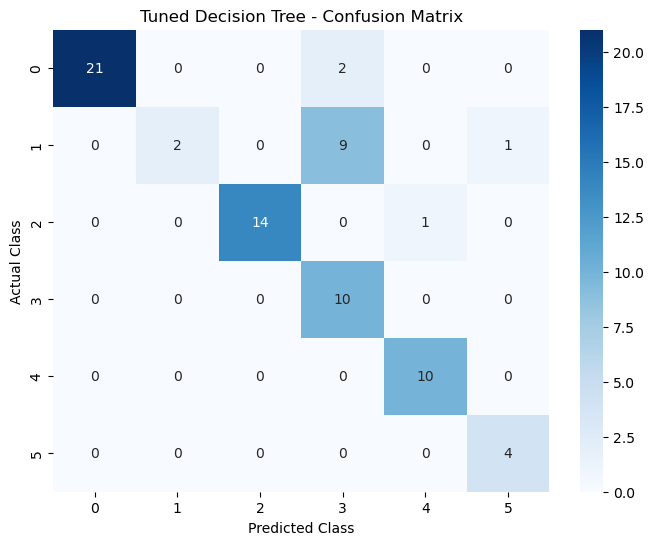

In [151]:
cm_dt = confusion_matrix(y_test, y_pred_dt_tuned)  # Create confusion matrix for the tuned Decision Tree model

plt.figure(figsize=(8, 6))  # Set figure size

sns.heatmap(
    cm_dt,  # Provide confusion matrix data
    annot=True,  # Display values inside each cell
    fmt="d",  # Format values as integers
    cmap="Blues"  # Apply blue color scheme
)

plt.title("Tuned Decision Tree - Confusion Matrix")  # Add chart title
plt.xlabel("Predicted Class")  # Label x-axis
plt.ylabel("Actual Class")  # Label y-axis
plt.show()  # Display confusion matrix

# Random Forest

In [152]:
from sklearn.ensemble import RandomForestClassifier  # Import Random Forest classification algorithm

In [153]:
rf_model = RandomForestClassifier(random_state=42)  # Initialize Random Forest model with a fixed random state
rf_model  # Display the model configuration

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [154]:
rf_model.fit(X_train_selected, y_train_smote)  # Train the Random Forest model using the training data
print("Random Forest Model Created Successfully")  # Display success message

Random Forest Model Created Successfully


In [155]:
y_pred_rf = rf_model.predict(X_test_selected)  # Predict skin disorder classes using the Random Forest model
y_pred_rf  # Display predicted results

array([4, 3, 4, 1, 4, 3, 4, 1, 2, 3, 1, 5, 5, 3, 5, 6, 6, 1, 5, 3, 1, 4,
       1, 1, 4, 3, 4, 1, 6, 4, 4, 5, 6, 2, 3, 1, 3, 5, 1, 1, 4, 1, 4, 1,
       1, 4, 1, 1, 5, 5, 1, 1, 1, 4, 3, 3, 1, 6, 4, 1, 1, 3, 5, 5, 4, 3,
       3, 4, 1, 3, 4, 4, 4, 5])

### Model Evaluation

In [156]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)  # Calculate Random Forest model accuracy

In [157]:
rf_precision = precision_score(y_test, y_pred_rf, average="weighted")# Calculate weighted precision for the Random Forest model

In [158]:
rf_recall = recall_score(y_test, y_pred_rf, average="weighted")# Calculate weighted recall for the Random Forest model

In [159]:
rf_f1 = f1_score(y_test, y_pred_rf, average="weighted")# Calculate weighted F1-score for the Random Forest model

In [160]:
print("Random Forest Model Evaluation Results")  # Display evaluation heading
print("-----------------")  # Print separator
print("Accuracy :", rf_accuracy)  # Display accuracy
print("Precision:", rf_precision)  # Display precision
print("Recall   :", rf_recall)  # Display recall
print("F1 Score :", rf_f1)  # Display F1-score

Random Forest Model Evaluation Results
-----------------
Accuracy : 0.8513513513513513
Precision: 0.9128927971033234
Recall   : 0.8513513513513513
F1 Score : 0.8228006331454607


In [161]:
rf_CR = classification_report(y_test, y_pred_rf)# Generate classification report for the Random Forest model
print(rf_CR)  # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.17      0.29        12
           3       1.00      0.93      0.97        15
           4       0.53      1.00      0.69        10
           5       0.91      1.00      0.95        10
           6       0.80      1.00      0.89         4

    accuracy                           0.85        74
   macro avg       0.87      0.85      0.80        74
weighted avg       0.91      0.85      0.82        74



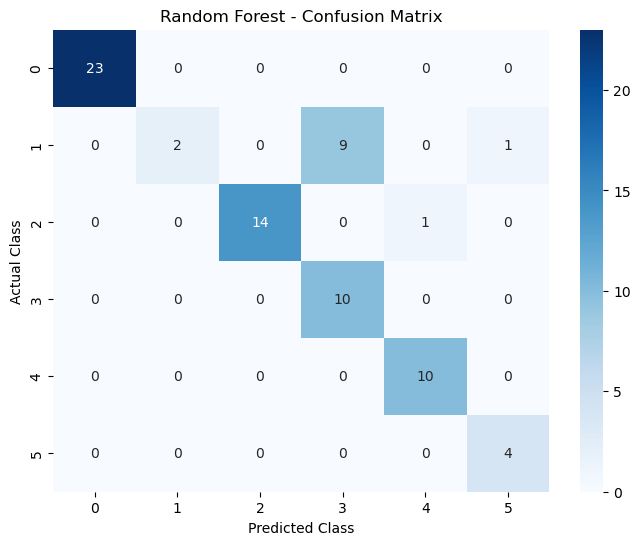

In [162]:
cm_rf = confusion_matrix(y_test, y_pred_rf)  # Create confusion matrix for the Random Forest model
plt.figure(figsize=(8, 6))  # Set figure size
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues")  # Display confusion matrix as a heatmap
plt.title("Random Forest - Confusion Matrix")  # Add chart title
plt.xlabel("Predicted Class")  # Label x-axis
plt.ylabel("Actual Class")  # Label y-axis
plt.show()  # Display the confusion matrix

### Random Forest with Hyperparameter Tuning

In [163]:
rf_param_grid = {  # Define hyperparameter values for Random Forest tuning
    "n_estimators": [100, 200, 300],  # Set the number of decision trees in the forest
    "max_depth": [None, 5, 10, 15],  # Set maximum depth of each tree; None allows unlimited depth
    "min_samples_split": [2, 5, 10],  # Set minimum samples required to split an internal node
    "min_samples_leaf": [1, 2, 4]  # Set minimum samples required at a leaf node
}

In [164]:
rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),  # Initialize Random Forest classifier
    param_grid=rf_param_grid,  # Provide hyperparameter combinations to test
    cv=5,  # Apply 5-fold cross-validation
    scoring="f1_weighted",  # Select the model with the best weighted F1-score
    n_jobs=-1  # Use all available CPU cores
)  # Configure GridSearchCV for hyperparameter tuning

In [165]:
rf_grid.fit(
    X_train_selected,  # Provide selected training features
    y_train_smote  # Provide SMOTE-resampled training target labels
)

print("Random Forest Hyperparameter Tuning Completed")  # Display completion message

Random Forest Hyperparameter Tuning Completed


In [166]:
print("Best Parameters:")  # Display the best hyperparameter settings
print(rf_grid.best_params_)  # Show the best parameter combination

print("Best Cross Validation F1 Score:")  # Display the best cross-validation F1-score
print(rf_grid.best_score_)  # Show the highest weighted F1-score from cross-validation

Best Parameters:
{'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Best Cross Validation F1 Score:
0.932332567854003


In [167]:
rf_tuned = rf_grid.best_estimator_  # Select the best-tuned Random Forest model
rf_tuned  # Display the tuned model and its best hyperparameters

,n_estimators,300
,criterion,'gini'
,max_depth,15
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [168]:
y_pred_rf_tuned = rf_tuned.predict(X_test_selected)  # Predict skin disorder classes using the tuned Random Forest model
y_pred_rf_tuned  # Display the predicted results

array([4, 3, 4, 1, 4, 3, 4, 1, 2, 3, 1, 5, 5, 3, 5, 6, 6, 1, 5, 3, 1, 4,
       1, 1, 4, 3, 4, 1, 6, 4, 4, 5, 6, 2, 3, 1, 3, 5, 1, 1, 4, 1, 4, 1,
       1, 4, 1, 1, 3, 5, 1, 1, 1, 4, 3, 3, 1, 6, 4, 1, 1, 3, 5, 5, 4, 3,
       3, 4, 1, 3, 4, 4, 4, 5])

### Model Evulation With Hyper Parameter Tunning

In [169]:
rf_tuned_accuracy = accuracy_score(y_test, y_pred_rf_tuned)# Calculate accuracy of the tuned Random Forest model

In [170]:
rf_tuned_precision = precision_score(y_test, y_pred_rf_tuned, average="weighted")# Calculate weighted precision for the tuned Random Forest model

In [171]:
rf_tuned_recall = recall_score(y_test, y_pred_rf_tuned, average="weighted")# Calculate weighted recall for the tuned Random Forest model

In [172]:
rf_tuned_f1 = f1_score(y_test, y_pred_rf_tuned, average="weighted")# Calculate weighted F1-score for the tuned Random Forest model

In [173]:
# Display the evaluation results of the tuned Random Forest model
print("Random Forest Model Evaluation with Hyperparameter Tuning Results")

print("---------------------------")  # Print a separator line

print("Accuracy :", rf_tuned_accuracy)  # Display the accuracy score
print("Precision:", rf_tuned_precision)  # Display the weighted precision score
print("Recall   :", rf_tuned_recall)  # Display the weighted recall score
print("F1 Score :", rf_tuned_f1)  # Display the weighted F1-score

Random Forest Model Evaluation with Hyperparameter Tuning Results
---------------------------
Accuracy : 0.8648648648648649
Precision: 0.9251778093883358
Recall   : 0.8648648648648649
F1 Score : 0.836225387949526


In [174]:
Rf_tuned_CR = classification_report(y_test, y_pred_rf_tuned)# Generate the classification report for the tuned Random Forest model
print(Rf_tuned_CR)# Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.17      0.29        12
           3       1.00      1.00      1.00        15
           4       0.53      1.00      0.69        10
           5       1.00      1.00      1.00        10
           6       0.80      1.00      0.89         4

    accuracy                           0.86        74
   macro avg       0.89      0.86      0.81        74
weighted avg       0.93      0.86      0.84        74



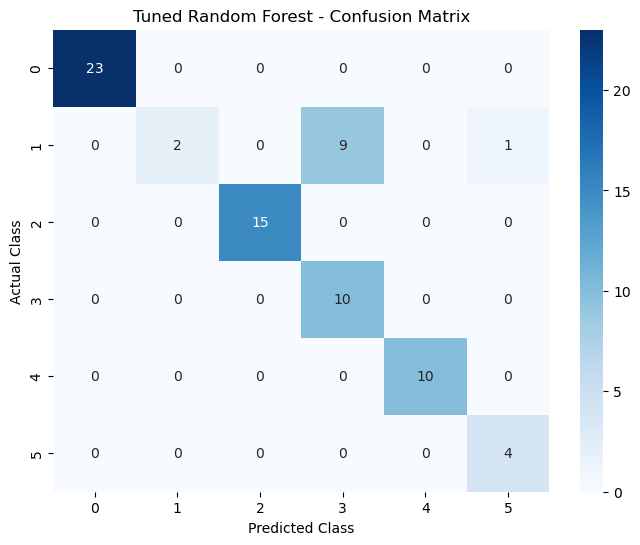

In [175]:
cm_rf_tuned = confusion_matrix(y_test, y_pred_rf_tuned)# Calculate the confusion matrix for the tuned Random Forest model
plt.figure(figsize=(8, 6))# Set the size of the confusion matrix plot
sns.heatmap(cm_rf_tuned, annot=True, fmt="d", cmap="Blues") # Display the confusion matrix as a heatmap with integer values
plt.title("Tuned Random Forest - Confusion Matrix") # Add a title to the confusion matrix
plt.xlabel("Predicted Class")# Label the x-axis with predicted classes
plt.ylabel("Actual Class")# Label the y-axis with actual classes
plt.show()# Display the confusion matrix plot

### SVM

In [176]:
from sklearn.svm import SVC  # Import Support Vector Classifier (SVC) for classification

In [177]:
svm_model = SVC(random_state=42)  # Create an SVM classification model with a fixed random state

svm_model  # Display the SVM model configuration

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [178]:
svm_model.fit(X_train_selected, y_train_smote) # Train the SVM model using the selected training features and SMOTE-balanced target data
print("SVM Model Created Successfully")# Display a success message after training the model

SVM Model Created Successfully


In [179]:
y_pred_svm = svm_model.predict(X_test_selected) # Predict the classes for the test dataset using the trained SVM model
y_pred_svm # Display the predicted class labels

array([6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6])

### Model Evalution

In [180]:
svm_accuracy = accuracy_score(y_test, y_pred_svm)# Calculate the accuracy score of the SVM model

In [181]:
svm_precision = precision_score(y_test, y_pred_svm, average="weighted")# Calculate weighted precision for the SVM model

In [182]:
svm_recall = recall_score(y_test, y_pred_svm, average="weighted")# Calculate weighted recall for the SVM model

In [183]:
svm_f1 = f1_score(y_test, y_pred_svm, average="weighted")# Calculate weighted F1-score for the SVM model

In [184]:
print("SVM Model Evaluation Results") # Display the evaluation results of the SVM model
print("-----------------")  # Print a separator line
print("Accuracy :", svm_accuracy)  # Display the accuracy score
print("Precision:", svm_precision)  # Display the weighted precision score
print("Recall   :", svm_recall)  # Display the weighted recall score
print("F1 Score :", svm_f1)  # Display the weighted F1-score

SVM Model Evaluation Results
-----------------
Accuracy : 0.05405405405405406
Precision: 0.0029218407596785976
Recall   : 0.05405405405405406
F1 Score : 0.005544005544005544


In [185]:
SVM_CR = classification_report(y_test, y_pred_svm) # Generate the classification report for the SVM model
print(SVM_CR) # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       0.00      0.00      0.00        23
           2       0.00      0.00      0.00        12
           3       0.00      0.00      0.00        15
           4       0.00      0.00      0.00        10
           5       0.00      0.00      0.00        10
           6       0.05      1.00      0.10         4

    accuracy                           0.05        74
   macro avg       0.01      0.17      0.02        74
weighted avg       0.00      0.05      0.01        74



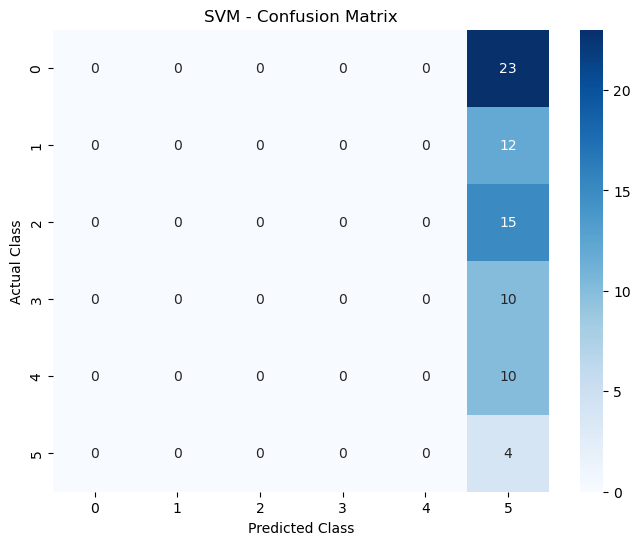

In [186]:
cm_svm = confusion_matrix(y_test, y_pred_svm) # Calculate the confusion matrix for the SVM model
plt.figure(figsize=(8, 6))# Set the size of the confusion matrix plot
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues") # Display the confusion matrix as a heatmap with integer values
plt.title("SVM - Confusion Matrix") # Add a title to the confusion matrix
plt.xlabel("Predicted Class") # Label the x-axis with predicted classes
plt.ylabel("Actual Class") # Label the y-axis with actual classes
plt.show() # Display the confusion matrix plot

### SVM With Hyperparameter Tuning

In [239]:
# Define the hyperparameter values to test for the SVM model
svm_param_grid = {
    "C": [0.1, 1, 10, 100],  # Test different regularization strengths
    "kernel": ["linear", "rbf", "poly"],  # Test different kernel functions
    "gamma": ["scale", "auto"]  # Test different gamma settings for kernel calculations
}

In [240]:
# Create GridSearchCV to find the best hyperparameters for the SVM model
svm_grid = GridSearchCV(
    estimator=SVC(random_state=42),  # Set the SVM classifier as the model
    param_grid=svm_param_grid,  # Provide the hyperparameter combinations to test
    cv=5,  # Use 5-fold cross-validation
    scoring="f1_weighted",  # Select the best model based on weighted F1-score
    n_jobs=-1  # Use all available CPU cores to speed up the search
)

In [241]:
svm_grid.fit(X_train_selected,y_train_smote) # Train GridSearchCV using the selected training features and SMOTE-balanced target data
print("SVM Hyperparameter Tuning Completed") # Display a message after hyperparameter tuning is completed

SVM Hyperparameter Tuning Completed


In [242]:
print("Best Parameters:")
print(svm_grid.best_params_) # Display the best hyperparameter combination found by GridSearchCV

print("Best Cross Validation F1 Score:")
print(svm_grid.best_score_) # Display the highest weighted F1-score achieved during cross-validation

Best Parameters:
{'C': 100, 'gamma': 'auto', 'kernel': 'rbf'}
Best Cross Validation F1 Score:
0.9112310071383775


In [243]:
svm_tuned = svm_grid.best_estimator_ # Store the best SVM model found during hyperparameter tuning
svm_tuned # Display the best-tuned SVM model

,C,100
,kernel,'rbf'
,degree,3
,gamma,'auto'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [244]:
y_pred_svm_tuned = svm_tuned.predict(X_test_selected) # Predict the classes for the test dataset using the tuned SVM model
y_pred_svm_tuned # Display the predicted class labels

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1])

### Model Evulation With Hyper Parameter Tunning

In [245]:
svm_tuned_accuracy = accuracy_score(y_test,y_pred_svm_tuned)# Calculate the accuracy score of the tuned SVM model

In [246]:
svm_tuned_precision = precision_score(y_test,y_pred_svm_tuned,average="weighted")# Calculate weighted precision for the tuned SVM model

In [247]:
svm_tuned_recall = recall_score(y_test,y_pred_svm_tuned,average="weighted")# Calculate weighted recall for the tuned SVM model

In [248]:
svm_tuned_f1 = f1_score(y_test,y_pred_svm_tuned,average="weighted")# Calculate weighted F1-score for the tuned SVM model

In [249]:
print("SVM Model Evaluation with Hyperparameter Tuning Results") # Display the evaluation results of the tuned SVM model
print("-----------------")  # Print a separator line
print("Accuracy :", svm_tuned_accuracy)  # Display the accuracy score
print("Precision:", svm_tuned_precision)  # Display the weighted precision score
print("Recall   :", svm_tuned_recall)  # Display the weighted recall score
print("F1 Score :", svm_tuned_f1)  # Display the weighted F1-score

SVM Model Evaluation with Hyperparameter Tuning Results
-----------------
Accuracy : 0.3108108108108108
Precision: 0.09660336011687362
Recall   : 0.3108108108108108
F1 Score : 0.14739481749791028


In [250]:
SVM_CR = classification_report(y_test,y_pred_svm_tuned)# Generate the classification report for the tuned SVM model
print(SVM_CR)# Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       0.31      1.00      0.47        23
           2       0.00      0.00      0.00        12
           3       0.00      0.00      0.00        15
           4       0.00      0.00      0.00        10
           5       0.00      0.00      0.00        10
           6       0.00      0.00      0.00         4

    accuracy                           0.31        74
   macro avg       0.05      0.17      0.08        74
weighted avg       0.10      0.31      0.15        74



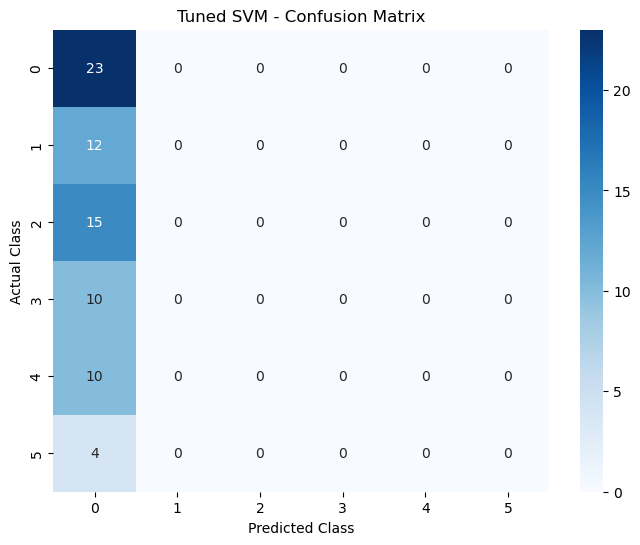

In [251]:
cm_svm_tuned = confusion_matrix(y_test,y_pred_svm_tuned) # Calculate the confusion matrix for the tuned SVM model
plt.figure(figsize=(8, 6))# Set the size of the confusion matrix plot
sns.heatmap(cm_svm_tuned,annot=True,fmt="d",cmap="Blues")# Display the confusion matrix as a heatmap with integer values
plt.title("Tuned SVM - Confusion Matrix")# Add a title to the confusion matrix
plt.xlabel("Predicted Class")# Label the x-axis with predicted classes
plt.ylabel("Actual Class")# Label the y-axis with actual classes
plt.show()# Display the confusion matrix plot

# MLP (Neural Network)

In [252]:
from sklearn.neural_network import MLPClassifier  # Import MLPClassifier for neural network-based classification

In [253]:
# Create the MLP neural network classification model
mlp_model = MLPClassifier(
    hidden_layer_sizes=(100,),  # Set one hidden layer containing 100 neurons
    activation="relu",  # Use ReLU activation function for the hidden layer
    solver="adam",  # Use the Adam optimizer to update model weights
    max_iter=1000,  # Allow up to 1000 iterations for model training
    random_state=42  # Set a fixed random state for reproducible results
)

In [254]:
mlp_model.fit(X_train_selected,y_train_smote) # Train the MLP neural network model using the selected training features and SMOTE-balanced target labels
print("MLP Model Created Successfully") # Display a success message after model training

MLP Model Created Successfully


In [255]:
y_pred_mlp = mlp_model.predict(X_test_selected) # Predict the classes for the test dataset using the trained MLP model
y_pred_mlp # Display the predicted class labels

array([4, 3, 4, 1, 4, 3, 4, 1, 4, 3, 1, 5, 5, 3, 5, 6, 6, 1, 5, 3, 1, 4,
       1, 1, 4, 3, 4, 1, 6, 4, 4, 5, 6, 4, 3, 1, 3, 5, 1, 1, 4, 1, 4, 1,
       1, 4, 1, 1, 3, 5, 1, 1, 1, 4, 3, 3, 1, 6, 4, 1, 1, 3, 5, 5, 4, 3,
       3, 4, 1, 3, 4, 4, 4, 5])

### Model Evaluation

In [256]:
mlp_accuracy = accuracy_score(y_test,y_pred_mlp)# Calculate the accuracy score of the MLP model

In [257]:
mlp_precision = precision_score(y_test,y_pred_mlp,average="weighted")# Calculate weighted precision for the MLP model

In [258]:
mlp_recall = recall_score(y_test,y_pred_mlp,average="weighted") # Calculate weighted recall for the MLP model

In [259]:
mlp_f1 = f1_score(y_test,y_pred_mlp,average="weighted")  # Calculate weighted F1-score for the MLP model

In [260]:
print("MLP in Model Evulation Results") # Display the evaluation results of the MLP model
print("-----------------") # Print a separator line
print("Accuracy :", mlp_accuracy)  # Display the accuracy score
print("Precision:", mlp_precision)  # Display the weighted precision score
print("Recall   :", mlp_recall)  # Display the weighted recall score
print("F1 Score :", mlp_f1)  # Display the weighted F1-score

MLP in Model Evulation Results
-----------------
Accuracy : 0.8378378378378378
Precision: 0.7562419562419562
Recall   : 0.8378378378378378
F1 Score : 0.7838806548483969


In [261]:
MLP_CR = classification_report(y_test,y_pred_mlp) # Generate the classification report for the MLP model
print(MLP_CR) # Display precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.00      0.00      0.00        12
           3       1.00      1.00      1.00        15
           4       0.48      1.00      0.65        10
           5       1.00      1.00      1.00        10
           6       0.80      1.00      0.89         4

    accuracy                           0.84        74
   macro avg       0.71      0.83      0.76        74
weighted avg       0.76      0.84      0.78        74



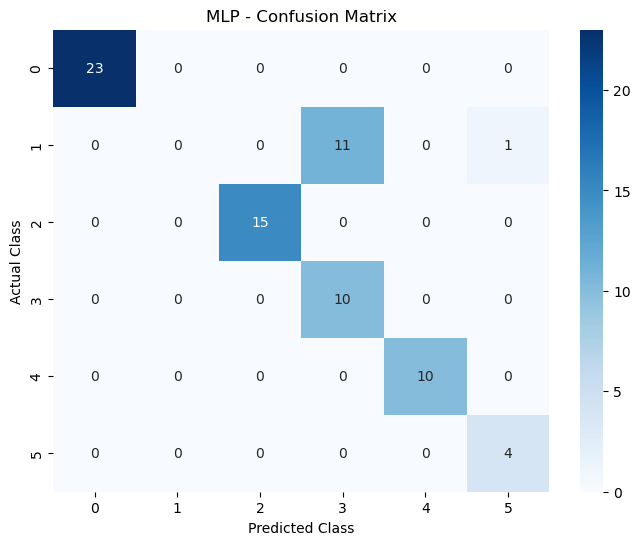

In [262]:
cm_mlp = confusion_matrix(y_test,y_pred_mlp) # Calculate the confusion matrix for the MLP model
plt.figure(figsize=(8, 6)) # Set the size of the confusion matrix plot
sns.heatmap(cm_mlp,annot=True,fmt="d",cmap="Blues") # Display the confusion matrix as a heatmap with integer values
plt.title("MLP - Confusion Matrix") # Add a title to the confusion matrix
plt.xlabel("Predicted Class") # Label he x-axis with predicted classes
plt.ylabel("Actual Class") # Label the y-axis with actual classes
plt.show() # Display the confusion matrix plot

### MLP With Hyperparameter Tuning

In [263]:
# Define the hyperparameter combinations to test for the MLP model
mlp_param_grid = {
    "hidden_layer_sizes": [
        (50,),       # Test one hidden layer with 50 neurons
        (100,),      # Test one hidden layer with 100 neurons
        (50, 50)     # Test two hidden layers with 50 neurons each
    ],
    "activation": [
        "relu",      # Use the ReLU activation function
        "tanh"       # Use the tanh activation function
    ],
    "solver": [
        "adam"       # Use the Adam optimizer for training
    ],
    "alpha": [
        0.0001,      # Test a small regularization strength
        0.001,       # Test a medium regularization strength
        0.01         # Test a higher regularization strength
    ],
    "learning_rate_init": [
        0.001,       # Test a lower initial learning rate
        0.01         # Test a higher initial learning rate
    ],
    "max_iter": [
        1000         # Allow up to 1000 training iterations
    ]
}

In [264]:
# Create GridSearchCV to find the best hyperparameters for the MLP model
mlp_grid = GridSearchCV(
    estimator=MLPClassifier(
        random_state=42  # Set a fixed random state for reproducible results
    ),
    param_grid=mlp_param_grid,  # Provide the hyperparameter combinations to test
    cv=5,  # Use 5-fold cross-validation
    scoring="f1_weighted",  # Select the best model based on weighted F1-score
    n_jobs=-1  # Use all available CPU cores to speed up the search
)

In [265]:
mlp_grid.fit(X_train_selected,y_train_smote) # Train GridSearchCV using the selected training features and SMOTE-balanced target data
print("MLP Hyperparameter Tuning Completed") # Display a message after hyperparameter tuning is completed

MLP Hyperparameter Tuning Completed


In [267]:
# Display the best hyperparameter combination found by GridSearchCV
print("Best Parameters:")
print(mlp_grid.best_params_)

# Display the best average weighted F1 score obtained during 5-fold cross-validation
print("Best Cross Validation F1 Score:")
print(mlp_grid.best_score_)

Best Parameters:
{'activation': 'tanh', 'alpha': 0.01, 'hidden_layer_sizes': (50, 50), 'learning_rate_init': 0.001, 'max_iter': 1000, 'solver': 'adam'}
Best Cross Validation F1 Score:
0.9037780249655173


In [268]:
mlp_tuned = mlp_grid.best_estimator_ # Store the best-performing MLP model found during hyperparameter tuning
mlp_tuned # Display the tuned MLP model with its best hyperparameters

,hidden_layer_sizes,"(50, ...)"
,activation,'tanh'
,solver,'adam'
,alpha,0.01
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,1000
,shuffle,True
,random_state,42


In [269]:
y_pred_mlp_tuned = mlp_tuned.predict(X_test_selected) # Predict the skin disorder classes for the test dataset using the tuned MLP model
y_pred_mlp_tuned # Display the predicted skin disorder classes from the tuned MLP model


array([4, 3, 4, 1, 4, 3, 4, 1, 2, 3, 1, 5, 5, 3, 5, 6, 6, 1, 5, 3, 1, 4,
       1, 1, 4, 3, 4, 1, 6, 4, 4, 5, 4, 4, 3, 1, 3, 5, 1, 1, 4, 1, 4, 1,
       1, 4, 1, 1, 3, 5, 1, 1, 1, 4, 3, 3, 1, 6, 4, 1, 1, 3, 5, 5, 4, 3,
       3, 4, 1, 3, 4, 4, 4, 5])

### Model Evaluation with Hyper Parameter Tunning

In [270]:
mlp_tuned_accuracy = accuracy_score(y_test,y_pred_mlp_tuned) # Calculate the accuracy of the tuned MLP model by comparing actual and predicted labels

In [271]:
mlp_tuned_precision = precision_score(y_test,y_pred_mlp_tuned,average="weighted")# Calculate th weighted precision of the tuned MLP model by comparing actual and predicted labels

In [272]:
mlp_tuned_recall = recall_score(y_test,y_pred_mlp_tuned,average="weighted")# Calculate the weighted recall of the tuned MLP model by comparing actual and predicted labels

In [273]:
mlp_tuned_f1 = f1_score(y_test,y_pred_mlp_tuned,average="weighted")# Calculate the weighted F1 score of the tuned MLP model using actual and predicted labels

In [274]:
print("MLP in Model Evulation with Hyper Parameter Tunning Results") # Display the evaluation results of the tuned MLP model
print("-----------------") # Print a separator line for better readability
print("Accuracy :", mlp_tuned_accuracy) # Display the accuracy score of the tuned MLP model
print("Precision:", mlp_tuned_precision) # Display the weighted precision score of the tuned MLP model
print("Recall   :", mlp_tuned_recall) # Display the weighted recall score of the tuned MLP model
print("F1 Score :", mlp_tuned_f1) # Display the weighted F1 score of the tuned MLP model

MLP in Model Evulation with Hyper Parameter Tunning Results
-----------------
Accuracy : 0.8513513513513513
Precision: 0.9292149292149292
Recall   : 0.8513513513513513
F1 Score : 0.8148346858024278


In [275]:
MLP_tuned_CR=classification_report(y_test,y_pred_mlp_tuned) # using the actual test labels and predicted labels
print(MLP_tuned_CR) # Display the classification report, including precision, recall, F1-score, and support for each class

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.08      0.15        12
           3       1.00      1.00      1.00        15
           4       0.48      1.00      0.65        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.85        74
   macro avg       0.91      0.85      0.80        74
weighted avg       0.93      0.85      0.81        74



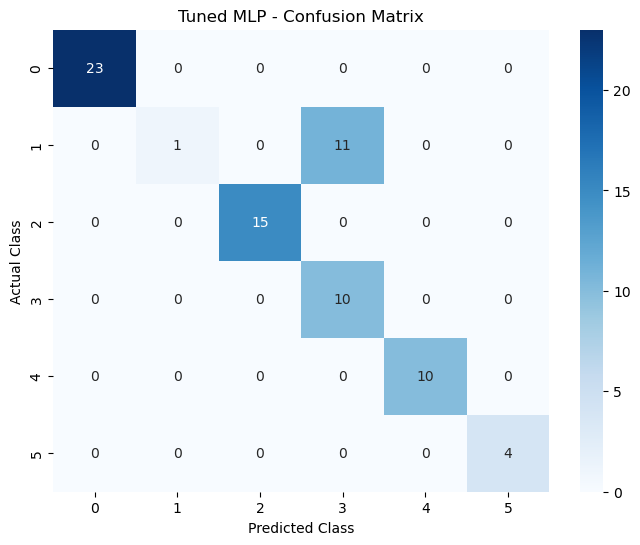

In [276]:
cm_mlp_tuned = confusion_matrix(y_test,y_pred_mlp_tuned)# Calculate the confusion matrix for the tuned MLP model
plt.figure(figsize=(8, 6)) # Set the figure size 
sns.heatmap(cm_mlp_tuned,annot=True,fmt="d",cmap="Blues")# Create a heatmap to visualize the confusion matrix
plt.title("Tuned MLP - Confusion Matrix") # Add a title to the confusion matrix
plt.xlabel("Predicted Class")# Label the x-axis with predicted class labels
plt.ylabel("Actual Class") # Label the y-axis with actual class labels
plt.show()# Display the confusion matrix heatmap

# Creating Model Comparison Report

In [277]:
# Create a DataFrame to compare the tuned performance of all six machine learning models
score = pd.DataFrame({
    # Store the names of the machine learning models
    "Model": [
        "LogisticRegression",
        "KNeighborsClassifier",
        "Support Vector Classifier",
        "DecisionTreeClassifier",
        "RandomForestClassifier",
        "ANN_MLPClassifier"
    ],

    # Store the tuned accuracy scores of each model
    "Accuracy": [
        lr_tuned_accuracy,
        knn_tuned_accuracy,
        dt_tuned_accuracy,
        rf_tuned_accuracy,
        svm_tuned_accuracy,
        mlp_tuned_accuracy
    ],

    # Store the tuned weighted precision scores of each model
    "Precision": [
        lr_tuned_precision,
        knn_tuned_precision,
        dt_tuned_precision,
        rf_tuned_precision,
        svm_tuned_precision,
        mlp_tuned_precision
    ],

    # Store the tuned weighted recall scores of each model
    "Recall": [
        lr_tuned_recall,
        knn_tuned_recall,
        dt_tuned_recall,
        rf_tuned_recall,
        svm_tuned_recall,
        mlp_tuned_recall
    ],

    # Store the tuned weighted F1 scores of each model
    "F1 Score": [
        lr_tuned_f1,
        knn_tuned_f1,
        dt_tuned_f1,
        rf_tuned_f1,
        svm_tuned_f1,
        mlp_tuned_f1
    ]
})

# Sort the models by F1 Score in descending order, placing the best score first
score = score.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

# Convert the evaluation scores into percentages and round them to two decimal places
for column in ["Accuracy", "Precision", "Recall", "F1 Score"]:
    score[column] = (score[column] * 100).round(2)

# Display the final comparison table of all tuned models
score

,Model,Accuracy,Precision,Recall,F1 Score
0,DecisionTreeClassifier,86.49,92.52,86.49,83.62
1,ANN_MLPClassifier,85.14,92.92,85.14,81.48
2,Support Vector Classifier,82.43,90.61,82.43,80.27
3,LogisticRegression,83.78,76.41,83.78,78.72
4,KNeighborsClassifier,48.65,51.88,48.65,47.24
5,RandomForestClassifier,31.08,9.66,31.08,14.74


In [278]:
best_model_name = score.loc[score["F1 Score"].idxmax(),"Model"] # Find the name of the model with the highest F1 Score
best_f1_score = score["F1 Score"].max() # Get the highest F1 Score from the comparison table
print("Best Model:", best_model_name) # Display the name of the best-performing model
print("Best F1 Score:", best_f1_score) # Display the highest F1 Score
print("Best F1 Score (%):", best_f1_score * 100) # Display the F1 Score as a percentage

Best Model: DecisionTreeClassifier
Best F1 Score: 83.62
Best F1 Score (%): 8362.0


# Conclusion of Model Comparison Report

The Skin Disorder Prediction project followed a complete machine learning workflow, including data understanding, exploratory data analysis, preprocessing, class imbalance handling, feature scaling, model development, hyperparameter tuning, and model evaluation.

The dataset contains six skin disorder classes with an imbalanced class distribution. Invalid values in the Age feature were handled using median imputation. SMOTE was incorporated into the training pipeline to address class imbalance without applying oversampling to the test data.

Multiple classification algorithms were evaluated, including Logistic Regression, KNN, SVM, Decision Tree, Random Forest, and ANN. Scaling was applied to models that are sensitive to feature magnitude, such as KNN, SVM, and ANN.

Hyperparameter tuning was performed using cross-validation. Model performance was evaluated using accuracy, precision, recall, weighted F1-score, classification reports, and confusion matrices.

The final model comparison was based on the test-set results and weighted F1-score rather than accuracy alone. The results should be interpreted carefully because model performance depends on the available dataset and may not directly generalize to unseen populations.

The developed system is a machine learning prediction model and should not be considered a replacement for professional medical diagnosis.

## Suggestions to the Doctors to identify the skin diseases of the patient at the earliest.

The exploratory analysis identifies associations between clinical/histopathological features and the six target classes. These observations can help understand patterns in the dataset; however, they should not be interpreted as independent medical diagnostic rules.

The machine learning model should be considered a predictive research tool and requires external validation before any real-world clinical application.

# Report on Challenges faced

This database contains 34 attributes, 33 of which are linear valued and one of them is nominal.this is a skin dieases dataset which 366 entries, 0 to 365 total columns and total 35 columns it has only one columns having object type and all of them are integers type. In this dataset most tough things are getting insights from data after working of 1 to 2 days I got insights.After thats every things are easy i did very easily and no more challenges I faced in this datasets.

# Revised workflow (recommended for final evaluation)

**Important:** Treat the earlier model scores as exploratory only. In the earlier workflow, imputation, scaling, feature selection and SMOTE were performed before cross-validation, and training/test transformations were inconsistent. The results from that workflow should not be used to claim a final best model. Run the cells in this section from top to bottom; they build a leakage-aware pipeline and regenerate the comparison from aligned result records.

## 1. Evidence-based EDA summary

This cell calculates the actual invalid Age count, class proportions, age summary, IQR outliers, and strongest class-wise feature differences from the dataframe. Use the printed values in the written report rather than generic chart descriptions. Since many clinical features are binary or ordinal, Pearson correlations are descriptive only and should not be interpreted as causal or necessarily linear relationships.

Dataset shape: (366, 35)
Invalid / missing Age values: 0 (0.00%)
\nClass counts:
class
1    112
2     61
3     72
4     49
5     52
6     20
Name: count, dtype: int64
\nClass percentages:
class
1    30.60
2    16.67
3    19.67
4    13.39
5    14.21
6     5.46
Name: proportion, dtype: float64
Imbalance ratio (largest/smallest class proportion): 5.60:1
\nAge summary:
count    366.000000
mean      36.289617
std       15.155749
min        0.000000
25%       25.000000
50%       36.000000
75%       48.000000
max       75.000000
Name: Age, dtype: float64
Age IQR fences: [-9.50, 82.50]
Potential Age outliers by IQR rule: 0
\nFeatures with largest range in class-wise means (descriptive, not causal):
Age                                        29.653
band-like_infiltrate                        2.722
vacuolisation_and_damage_of_basal_layer     2.306
saw-tooth_appearance_of_retes               2.292
fibrosis_of_the_papillary_dermis            2.288
polygonal_papules                           2.278


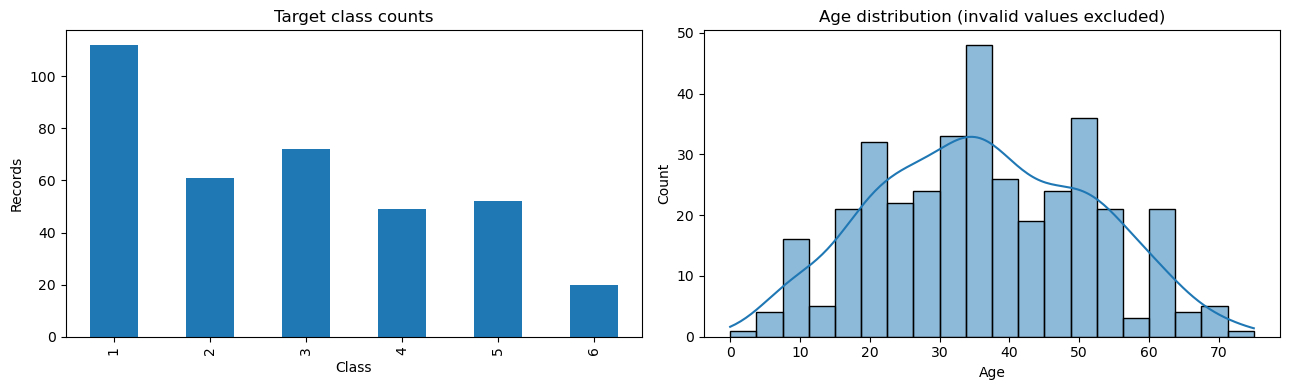

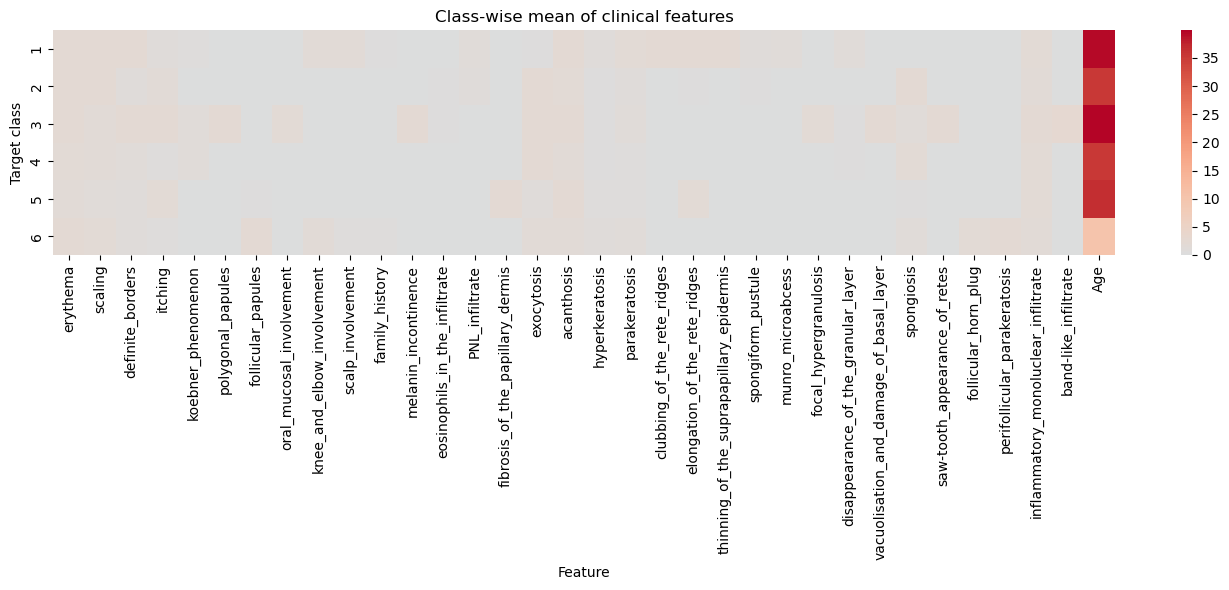

In [279]:
# Work on a fresh copy so the earlier exploratory transformations do not affect this workflow.
eda_df = df.copy()
age_raw = eda_df["Age"].astype(str).str.strip()
invalid_age_mask = age_raw.eq("?") | age_raw.eq("")
eda_df["Age"] = pd.to_numeric(eda_df["Age"], errors="coerce")

print("Dataset shape:", eda_df.shape)
print("Invalid / missing Age values:", int(eda_df["Age"].isna().sum()),
      f"({eda_df['Age'].isna().mean() * 100:.2f}%)")
print("\\nClass counts:")
print(eda_df["class"].value_counts().sort_index())
print("\\nClass percentages:")
print((eda_df["class"].value_counts(normalize=True).sort_index() * 100).round(2))
class_pct = eda_df["class"].value_counts(normalize=True)
print(f"Imbalance ratio (largest/smallest class proportion): "
      f"{class_pct.max() / class_pct.min():.2f}:1")
print("\\nAge summary:")
print(eda_df["Age"].describe())

age_valid = eda_df["Age"].dropna()
if not age_valid.empty:
    q1, q3 = age_valid.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_mask = (age_valid < lower) | (age_valid > upper)
    print(f"Age IQR fences: [{lower:.2f}, {upper:.2f}]")
    print(f"Potential Age outliers by IQR rule: {int(outlier_mask.sum())}")

feature_cols_eda = [c for c in eda_df.columns if c != "class"]
class_means = eda_df.groupby("class")[feature_cols_eda].mean(numeric_only=True)
if class_means.shape[0] > 1:
    separation = (class_means.max(axis=0) - class_means.min(axis=0)).sort_values(ascending=False)
    print("\\nFeatures with largest range in class-wise means (descriptive, not causal):")
    print(separation.head(10).round(3))

# Focused, readable plots instead of a single crowded 7x5 grid.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
eda_df["class"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Target class counts")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Records")
sns.histplot(data=eda_df, x="Age", bins=20, kde=True, ax=axes[1])
axes[1].set_title("Age distribution (invalid values excluded)")
plt.tight_layout()
plt.show()

# Class-wise feature means can reveal descriptive differences; values are not diagnostic rules.
plt.figure(figsize=(14, 6))
sns.heatmap(class_means, cmap="coolwarm", center=class_means.stack().median())
plt.title("Class-wise mean of clinical features")
plt.xlabel("Feature")
plt.ylabel("Target class")
plt.tight_layout()
plt.show()

## 2. Leakage-aware preprocessing and model evaluation

- Split the original data first using stratification.
- Convert invalid numeric values to missing; impute with the **training-fold median** using `SimpleImputer`, not a hard-coded value.
- Apply scaling, feature selection and (where used) SMOTE inside an imbalanced-learn pipeline so each cross-validation fold learns its own transformations.
- Keep the test set untouched until final evaluation.
- SMOTE interpolates values and may create unrealistic combinations for binary/ordinal clinical variables. Therefore, the comparison below evaluates both a class-weighted / unresampled baseline and an SMOTE pipeline for models that support it. Treat any synthetic sampling result as exploratory, and prefer class weighting or domain-aware resampling if synthetic feature combinations are not clinically meaningful.

Train shape: (292, 34) | Test shape: (74, 34)
Training class counts:
 class
1    89
2    49
3    57
4    39
5    42
6    16
Name: count, dtype: int64
Test class counts:
 class
1    23
2    12
3    15
4    10
5    10
6     4
Name: count, dtype: int64

Logistic Regression | best CV weighted F1: 0.9796
Best parameters: {'clf__C': 10, 'selector__k': 'all'}
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.83      0.91        12
           3       1.00      0.93      0.97        15
           4       0.77      1.00      0.87        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.96      0.96      0.96        74
weighted avg       0.97      0.96      0.96        74



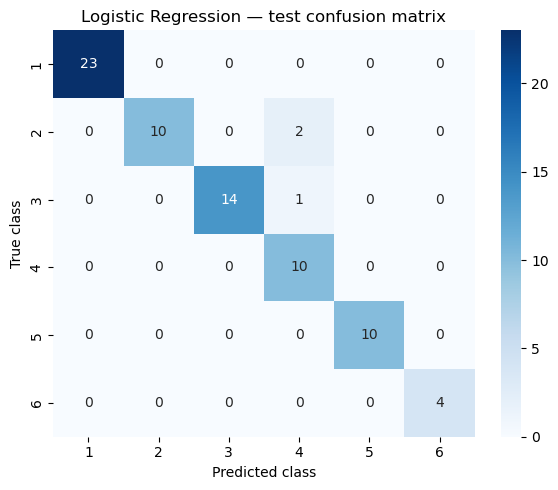


KNN | best CV weighted F1: 0.9757
Best parameters: {'clf__n_neighbors': 5, 'clf__weights': 'distance', 'selector__k': 20}
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.85      0.92      0.88        12
           3       1.00      1.00      1.00        15
           4       0.89      0.80      0.84        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.96      0.95      0.95        74
weighted avg       0.96      0.96      0.96        74



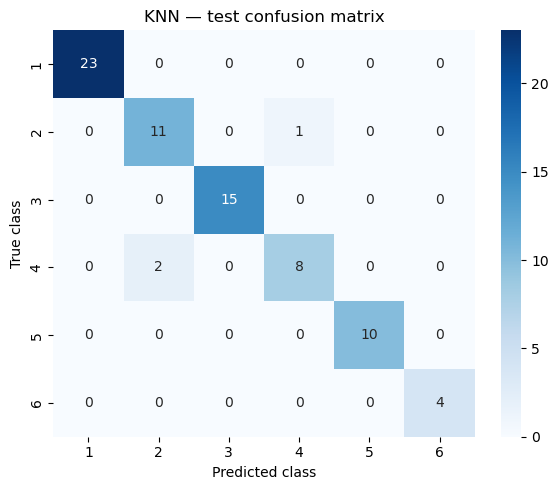


Decision Tree | best CV weighted F1: 0.9547
Best parameters: {'clf__max_depth': 10, 'clf__min_samples_leaf': 1, 'selector__k': 'all'}
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.83      0.91        12
           3       1.00      0.93      0.97        15
           4       0.91      1.00      0.95        10
           5       0.91      1.00      0.95        10
           6       0.80      1.00      0.89         4

    accuracy                           0.96        74
   macro avg       0.94      0.96      0.94        74
weighted avg       0.96      0.96      0.96        74



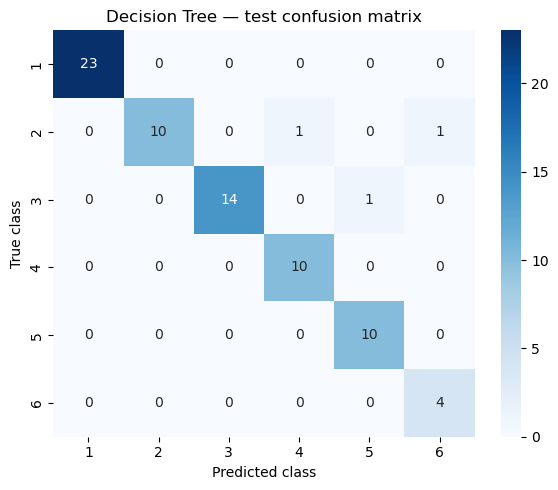


Random Forest | best CV weighted F1: 0.9826
Best parameters: {'clf__max_depth': None, 'clf__min_samples_leaf': 2, 'selector__k': 'all'}
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.91      0.83      0.87        12
           3       1.00      1.00      1.00        15
           4       0.90      0.90      0.90        10
           5       1.00      1.00      1.00        10
           6       0.80      1.00      0.89         4

    accuracy                           0.96        74
   macro avg       0.93      0.96      0.94        74
weighted avg       0.96      0.96      0.96        74



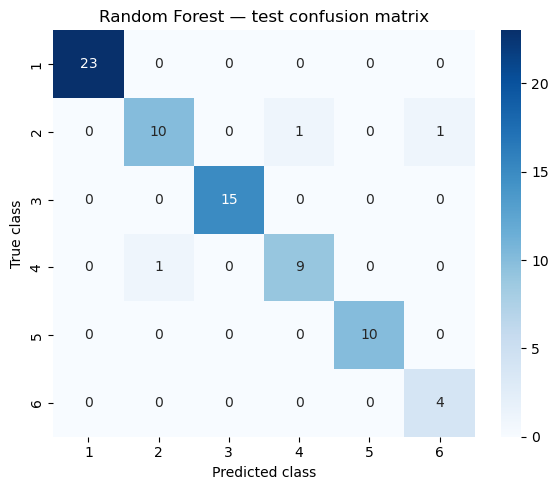


SVM | best CV weighted F1: 0.9825
Best parameters: {'clf__C': 5, 'clf__kernel': 'rbf', 'selector__k': 20}
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.92      0.96        12
           3       1.00      1.00      1.00        15
           4       0.91      1.00      0.95        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.99        74
   macro avg       0.98      0.99      0.98        74
weighted avg       0.99      0.99      0.99        74



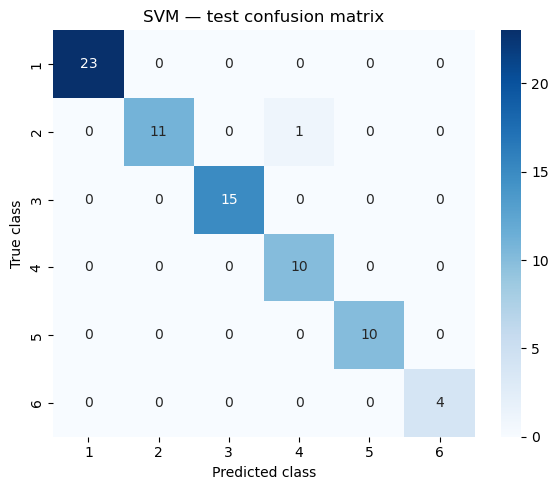


MLP | best CV weighted F1: 0.9430
Best parameters: {'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (100,), 'selector__k': 'all'}
              precision    recall  f1-score   support

           1       0.96      0.96      0.96        23
           2       0.71      0.83      0.77        12
           3       1.00      1.00      1.00        15
           4       0.90      0.90      0.90        10
           5       1.00      0.80      0.89        10
           6       1.00      1.00      1.00         4

    accuracy                           0.92        74
   macro avg       0.93      0.91      0.92        74
weighted avg       0.93      0.92      0.92        74



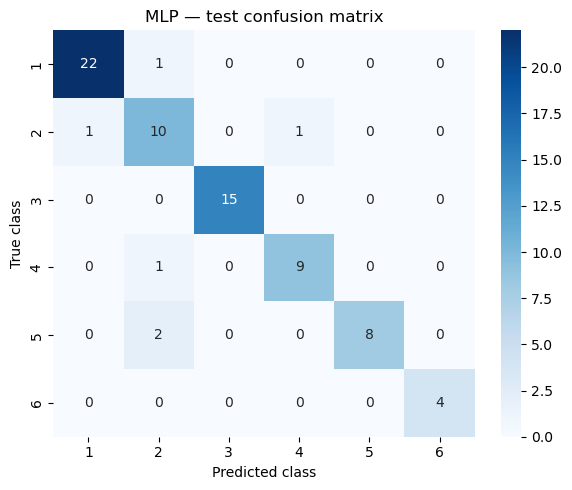

,Model,CV weighted F1,Test accuracy,Test balanced accuracy,Test weighted precision,Test weighted recall,Test weighted F1,Test macro F1
0,SVM,0.9825,0.9865,0.9861,0.9877,0.9865,0.9865,0.9848
1,Logistic Regression,0.9796,0.9595,0.9611,0.9688,0.9595,0.9606,0.9574
2,KNN,0.9757,0.9595,0.9528,0.9600,0.9595,0.9592,0.9537
3,Decision Tree,0.9547,0.9595,0.9611,0.9646,0.9595,0.9594,0.9447
4,Random Forest,0.9826,0.9595,0.9556,0.9609,0.9595,0.9593,0.9431
5,MLP,0.9430,0.9189,0.9150,0.9266,0.9189,0.9205,0.9191



Best model by test macro F1 (tie-break: balanced accuracy, then weighted F1): SVM
Test macro F1: 0.9848
Test weighted F1 (%): 98.65%


In [281]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)

# Rebuild X/y from the untouched dataframe.
# All predictor columns are expected to be numeric/ordinal.
model_df = df.copy()
X_all = model_df.drop(columns=["class"]).copy()

for col in X_all.columns:
    X_all[col] = pd.to_numeric(X_all[col], errors="coerce")

y_all = model_df["class"].astype(int)

# Split before fitting preprocessing or feature selection.
X_train_raw, X_test_raw, y_train_final, y_test_final = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    random_state=42,
    stratify=y_all,
)

print("Train shape:", X_train_raw.shape, "| Test shape:", X_test_raw.shape)
print("Training class counts:\n", y_train_final.value_counts().sort_index())
print("Test class counts:\n", y_test_final.value_counts().sort_index())

n_features = X_train_raw.shape[1]

# Keep numeric k values no larger than the feature count, then add "all".
# Do not sort this list: Python cannot compare integers with the string "all".
k_candidates = [k for k in (10, 20) if k <= n_features] + ["all"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Models use class weights where supported. No SMOTE is applied.
model_specs = {
    "Logistic Regression": (
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42,
        ),
        {"clf__C": [0.1, 1, 10]},
    ),
    "KNN": (
        KNeighborsClassifier(),
        {
            "clf__n_neighbors": [3, 5, 7],
            "clf__weights": ["uniform", "distance"],
        },
    ),
    "Decision Tree": (
        DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42,
        ),
        {
            "clf__max_depth": [None, 5, 10],
            "clf__min_samples_leaf": [1, 2, 4],
        },
    ),
    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced",
            n_estimators=200,
            random_state=42,
            n_jobs=-1,
        ),
        {
            "clf__max_depth": [None, 10],
            "clf__min_samples_leaf": [1, 2],
        },
    ),
    "SVM": (
        SVC(
            class_weight="balanced",
            random_state=42,
        ),
        {
            "clf__C": [0.5, 1, 5],
            "clf__kernel": ["linear", "rbf"],
        },
    ),
    "MLP": (
        MLPClassifier(
            max_iter=1500,
            early_stopping=True,
            random_state=42,
        ),
        {
            "clf__hidden_layer_sizes": [(50,), (100,)],
            "clf__alpha": [0.0001, 0.01],
        },
    ),
}

results = []
best_estimators = {}
class_labels = sorted(y_all.unique())

for model_name, (estimator, model_param_grid) in model_specs.items():
    # Imputation, scaling, and feature selection are fit inside each CV fold.
    pipe = SklearnPipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            (
                "selector",
                SelectKBest(score_func=mutual_info_classif, k="all"),
            ),
            ("clf", estimator),
        ]
    )

    param_grid = dict(model_param_grid)
    param_grid["selector__k"] = k_candidates

    search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring="f1_weighted",
        cv=cv,
        n_jobs=-1,
        refit=True,
        error_score="raise",
    )

    search.fit(X_train_raw, y_train_final)
    pred = search.predict(X_test_raw)

    best_estimators[model_name] = search.best_estimator_

    results.append(
        {
            "Model": model_name,
            "CV weighted F1": search.best_score_,
            "Test accuracy": accuracy_score(y_test_final, pred),
            "Test balanced accuracy": balanced_accuracy_score(
                y_test_final, pred
            ),
            "Test weighted precision": precision_score(
                y_test_final,
                pred,
                average="weighted",
                zero_division=0,
            ),
            "Test weighted recall": recall_score(
                y_test_final,
                pred,
                average="weighted",
                zero_division=0,
            ),
            "Test weighted F1": f1_score(
                y_test_final,
                pred,
                average="weighted",
                zero_division=0,
            ),
            "Test macro F1": f1_score(
                y_test_final,
                pred,
                average="macro",
                zero_division=0,
            ),
            "Best parameters": search.best_params_,
        }
    )

    print(f"\n{model_name} | best CV weighted F1: {search.best_score_:.4f}")
    print("Best parameters:", search.best_params_)
    print(
        classification_report(
            y_test_final,
            pred,
            labels=class_labels,
            zero_division=0,
        )
    )

    cm = confusion_matrix(y_test_final, pred, labels=class_labels)
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
    )
    plt.title(f"{model_name} — test confusion matrix")
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.tight_layout()
    plt.show()

results_df = (
    pd.DataFrame(results)
    .sort_values(
        by=["Test macro F1", "Test balanced accuracy", "Test weighted F1"],
        ascending=False,
    )
    .reset_index(drop=True)
)

display_cols = [c for c in results_df.columns if c != "Best parameters"]
display(results_df[display_cols].round(4))

print(
    "\nBest model by test macro F1 "
    "(tie-break: balanced accuracy, then weighted F1):",
    results_df.loc[0, "Model"],
)
print("Test macro F1:", f"{results_df.loc[0, 'Test macro F1']:.4f}")
print(
    "Test weighted F1 (%):",
    f"{results_df.loc[0, 'Test weighted F1'] * 100:.2f}%",
)


## 3. How to report the final result

After running the revised evaluation cell, copy the **actual output** from `results_df` into the report. Do not invent scores or retain the earlier comparison table. Macro F1 is the primary selection criterion here because it gives each disease class equal weight; balanced accuracy and per-class recall should be checked before making the final choice. If the model with the highest macro F1 performs poorly on a particular class, state that limitation explicitly rather than relying only on a single overall score.

The revised workflow uses a class-weighted, non-SMOTE primary comparison to avoid synthetic interpolation of ordinal/binary symptoms. If you additionally test SMOTE, use an `imblearn.pipeline.Pipeline` with steps ordered as imputation → scaling → feature selection → SMOTE → classifier, and put the entire pipeline inside cross-validation. Compare it against this baseline using the same folds and selection metrics.

## Revised conclusion template

The skin-disorder dataset contains six target classes and a mixture of age and encoded clinical/histopathological features. Invalid Age entries are converted to missing values and imputed using medians learned from training folds. Stratified splitting preserves class proportions, while imputation, scaling and feature selection are fitted within cross-validation to reduce leakage. The revised comparison evaluates Logistic Regression, KNN, Decision Tree, Random Forest, SVM and MLP using cross-validation weighted F1, test macro F1, balanced accuracy, weighted F1 and per-class classification reports.

**Complete this paragraph after running the revised workflow:** The model selected by test macro F1 was **[model name]**, with macro F1 **[value]**, balanced accuracy **[value]**, and weighted F1 **[value]**. Its per-class recall was **[summarize classes from the classification report]**. These results describe performance on this dataset's held-out split and are not evidence of clinical readiness.

Important limitations include the small dataset, potential sampling bias, encoded symptom features that may not generalize to other clinical settings, and lack of independent external validation. The dataset and models should not be used as a standalone diagnostic tool. Next steps are to validate on an independent dataset, assess probability calibration, review false negatives with qualified clinicians, and document data provenance and clinical suitability.

# _The project follows a standard end-to-end Machine Learning classification lifecycle:_

# Problem Definition & Business Case:

* Formulate a predictive classification task to classify dermatological cases into one of six distinct erythematosquamous skin diseases using clinical and histopathological attributes.

1. Data Acquisition & Exploration:Load the dataset (skindisorderdata.csv), check dimensionality ((366, 35)), inspect data types, column names, and check for missing and duplicate values.

2. Data Quality & Hygiene Analysis:Inspect data types: All clinical/histopathological features are encoded as integers (int64), while the Age column is read as an object due to missing/special character markers (?).
Verify missing values: Standard .isnull().sum() outputs 0 initially because missing entries in Age are recorded as string characters ('?').

3. Exploratory Data Analysis (EDA):Target Distribution: Analyze the target variable class via frequency counts and percentage distributions (value_counts(normalize=True)) along with count plots to evaluate class imbalance.

4. Univariate & Bivariate Feature Analysis:Visualize patient age distribution using histograms and kernel density estimation (KDE).
Analyze age variance across target disease classes using boxplots.
Examine value ranges for all 33 clinical/histopathological features (graded on a scale of 0 to 3, and family history as 0 or 1).

5. Data Preprocessing & Feature Engineering:Clean Age by replacing '?' with NaN, imputing missing values (typically via median or mean), and converting the column to a numeric data type (int64/float64).
Perform feature scaling/standardization if distance-based models are utilized.

6. Model Training & Evaluation:Split data into train and test sets using stratified sampling to preserve minority class ratios.
Train supervised multi-class classification algorithms, tune hyperparameters, and evaluate using accuracy, precision, recall, F1-score, and confusion matrices.

# Dataset Information
The project uses the standard Dermatology / Skin Disorder Dataset containing 366 records and 35 columns (34 input features and 1 target class):

1. Target Variable (class): Multi-class target containing 6 disease classes:
* Psoriasis: 112 cases (~30.6%)
* Seborrheic Dermatitis: 61 cases (~16.7%)
* Lichen Planus: 72 cases (~19.7%)
* Pityriasis Rosea: 49 cases (~13.4%)
* Chronic Dermatitis: 52 cases (~14.2%)
* Pityriasis Rubra Pilaris: 20 cases (~5.5%)

2. Input Features:

Clinical Features: Erythema, scaling, definite borders, itching, Koebner phenomenon, polygonal papules, follicular papules, oral mucosal involvement, knee and elbow involvement, scalp involvement, family history, and age.   

3. Histopathological Features: Melanin incontinence, eosinophils in the infiltrate, PNL infiltrate, fibrosis of the papillary dermis, exocytosis, acanthosis, hyperkeratosis, parakeratosis, clubbing of the rete ridges, elongation of the rete ridges, thinning of the suprapapillary epidermis, spongiform pustule, Munro microabscess, focal hypergranulosis, disappearance of the granular layer, vacuolisation and damage of basal layer, spongiosis, saw-tooth appearance of retes, follicular horn plug, perifollicular parakeratosis, inflammatory mononuclear infiltrate, and band-like infiltrate.   

4. Feature Encoding & Attributes:
Most clinical and histopathological attributes are rated ordinally from 0 to 3 (0: absent, 1 & 2: intermediate degree, 3: maximum presence).
family_history is binary (1: present in family, 0: absent).
Age is continuous numeric (ranging from children under 10 up to 75 years old, with missing values indicated as '?').

 # Models Used (Recommended & Standard Workflow)
For this specific tabular dataset, the standard multi-class classification models applied include:

1. Logistic Regression (Multinomial / One-vs-Rest): Serves as a linear baseline for multi-class classification.
2. Random Forest Classifier: Handles non-linear feature interactions, robust to feature scale differences, and evaluates feature importance.
3. Gradient Boosting / XGBoost / LightGBM: Optimized tree ensembles that handle class imbalance effectively and typically achieve top-tier validation accuracy on this dataset.
4. Support Vector Machine (SVM / SVC with RBF kernel): Effective for tabular clinical datasets where boundary margins between disease symptoms are distinct.
5. K-Nearest Neighbors (KNN): Distance-based classification across the ordinal symptom feature space.
6. Evaluation Metrics: Overall Accuracy, Class-wise Precision, Recall, Macro/Weighted F1-score, and a Multi-class Confusion Matrix to check misclassifications between symptomatically similar classes (e.g., Psoriasis vs. Seborrheic Dermatitis).

# Conclusion & Key Takeaways
* Clinical Viability: Machine learning models can accurately distinguish between clinically overlapping erythematosquamous diseases by leveraging combined clinical and histopathology attributes.
* Data Imbalance: The dataset displays noticeable imbalance—Class 1 (Psoriasis) represents ~30.6% of samples, whereas Class 6 (Pityriasis Rubra Pilaris) represents only ~5.5% (20 samples). Utilizing class weights or stratified splits is necessary to avoid poor sensitivity on minority classes.
* Data Cleaning Prerequisite: The Age column requires conversion from object to numeric after handling '?' placeholder tokens to avoid pipeline failures during modeling.
* Diagnostic Impact: Integrating both surface clinical observations and biopsy histopathology markers provides a complementary feature set that yields high multi-class predictive performance, aiding dermatologists in differential diagnosis.